# Modul 5: Convolutional Neural Network Dasar

**Nama:** Ahmad Farhan Ghani
**NIM:** 123450121
**Kelas:** RA
**Tanggal:** 2026-10-14

Simpan berkas ini sebagai `M05_NIM.ipynb` sebelum mulai mengerjakan.

## Petunjuk

Notebook ini memiliki tiga jenis bagian. Tanda di akhir judul menunjukkan jenisnya.

| Tanda | Bagian | Yang Anda lakukan |
|:---|:---|:---|
| **Terbimbing** | Pre-lab, A–E | Jawaban lengkap Prosedur Praktikum Terbimbing sudah tersedia, termasuk pelatihan CNN baseline. Jalankan, baca kodenya, lalu cocokkan keluarannya dengan tab **Materi** modul. |
| **Latihan Mandiri di Lab** | Latihan | Dikerjakan sendiri di laboratorium setelah bagian terbimbing. |
| **Tugas Individu** | T1–T4 dan Pertanyaan analisis | Dikerjakan di luar sesi dan dikumpulkan lewat Tugas. |

1. Isi identitas di atas dan `NIM` pada sel pertama. Hanya itu isian pada bagian terbimbing. `DATASET = 'fashion'` sudah diatur untuk laptop tanpa GPU.
2. Tekan **Siapkan dataset di laptop** di halaman modul agar Fashion-MNIST tersedia di `data/raw`. Notebook tidak mengunduh apa pun.
3. Tekan **Restart**, lalu **Run all**. Seluruh sel terbimbing berjalan di kernel Deep Learning (PyTorch CPU) dan berhenti di sel Latihan pertama yang masih berisi `TODO`.
4. Keluaran yang tidak bergantung pada NIM, misalnya hitungan cross-correlation, gradien, dan tabel anatomi, harus sama persis dengan naskah. Tensor acak, split data, dan hasil training bergantung pada seed NIM, sedangkan waktu bergantung pada perangkat.
5. Pada bagian Latihan dan Tugas, ganti seluruh penanda `TODO` dan jangan menghapus sel pemeriksaan `cek(...)` atau `assert`. Implementasi manual hanya boleh memakai indexing, perkalian elemen, penjumlahan, `F.pad`, dan `torch.flip`; verifikasi memakai `torch.float64`. Validation set dipakai untuk memilih model, dan test set hanya dipakai satu kali pada Tugas T4.
6. Sebelum mengumpulkan, jalankan **Restart** lalu **Run all** sampai seluruh sel selesai tanpa galat. Luaran: `M05_NIM.ipynb`, `M05_NIM.pdf`, dan `M05_NIM_metrics.csv`; sebutkan pada laporan bahwa dataset yang dipakai Fashion-MNIST.

In [2]:
import platform
import random
import statistics
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import Markdown, display
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import CIFAR10, FashionMNIST

# Kernel Workbench menangkap figure di akhir setiap sel; plt.show() dipertahankan
# agar notebook tetap berjalan di Jupyter biasa, tanpa peringatan backend Agg.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

DATASET = 'fashion'      # Workbench (CPU): Fashion-MNIST dari data/raw; 'cifar10' hanya bila datanya tersedia
NIM = '123450121'  # NIM lengkap Ahmad Farhan Ghani
assert NIM.isdigit() and len(NIM) >= 4, 'Isi NIM dengan angka sebelum melanjutkan.'
SEED = int(str(NIM)[-4:]) if str(NIM).isdigit() else 42
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DT = torch.float64

def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def cek(nama, hasil, acuan):
    """Sel pemeriksaan: shape harus sama dan nilai lolos torch.allclose."""
    assert hasil is not None and acuan is not None, f'{nama}: nilai belum diisi (masih None)'
    hasil = torch.as_tensor(hasil.detach() if torch.is_tensor(hasil) else hasil, dtype=DT)
    acuan = torch.as_tensor(acuan.detach() if torch.is_tensor(acuan) else acuan, dtype=DT)
    ok = hasil.shape == acuan.shape and torch.allclose(hasil, acuan)
    print(f'[{"OK" if ok else "GAGAL"}] {nama}: shape {tuple(hasil.shape)}')
    assert ok, f'{nama} tidak cocok dengan acuan'

def ukur(fungsi, ulang=10):
    """Median waktu eksekusi `fungsi` dalam detik setelah satu pemanasan."""
    fungsi()
    waktu = []
    for _ in range(ulang):
        mulai = time.perf_counter()
        fungsi()
        waktu.append(time.perf_counter() - mulai)
    return statistics.median(waktu)

seed_everything(SEED)
pd.set_option('display.precision', 4)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
print({'python': platform.python_version(), 'torch': torch.__version__,
       'device': str(DEVICE), 'dataset': DATASET, 'seed': SEED})

{'python': '3.14.5', 'torch': '2.14.0+cpu', 'device': 'cpu', 'dataset': 'fashion', 'seed': 121}


## Pre-lab · Terbimbing

a. **$p=1$, $s=2$.** Shape $\lfloor(5+2-3)/2\rfloor+1=3$, jadi keluaran $3\times3$. Jendela pertama pada citra berpadding adalah
$\left[\begin{smallmatrix}0&0&0\\0&1&2\\0&0&1\end{smallmatrix}\right]$, sehingga
$Y_{0,0}=(0\cdot1+0\cdot0+0\cdot(-1))+(0\cdot2+1\cdot1+2\cdot0)+(0\cdot0+0\cdot(-1)+1\cdot1)=2$.
Seluruh keluaran:
$$\begin{bmatrix}2&3&4\\0&2&6\\3&0&5\end{bmatrix}.$$

b. **Kolom ke-4** berasal dari jendela yang berpusat di $(2,2)$, yaitu baris 1–3 dan kolom 1–3:
$\left[\begin{smallmatrix}1&3&2\\1&0&1\\0&2&3\end{smallmatrix}\right]$, dibaca per baris menjadi $(1,3,2,1,0,1,0,2,3)^\top$.

c. **Parameter** $32\cdot3\cdot3^2+32=896$. **Perkalian** $C_\text{out}C_\text{in}k^2H_\text{keluar}W_\text{keluar}=32\cdot3\cdot9\cdot32\cdot32=884\,736$ per citra, karena $p=1$ mempertahankan ukuran $32\times32$.

d. Kernel dipelajari dari data. Model yang memakai konvolusi matematis cukup mempelajari kernel yang diputar $180^\circ$ untuk menghasilkan fungsi yang sama persis dengan model cross-correlation. Himpunan fungsi yang dapat dinyatakan kedua operasi identik, sehingga loss terbaik yang dapat dicapai juga sama; yang berbeda hanya orientasi kernel hasil pelatihan.

## A. Cross-correlation manual · Terbimbing

$$\mathbf{X}=\begin{bmatrix}1&2&0&1&3\\0&1&3&2&1\\2&1&0&1&2\\1&0&2&3&0\\3&1&1&0&2\end{bmatrix},\qquad
\mathbf{K}=\begin{bmatrix}1&0&-1\\2&1&0\\0&-1&1\end{bmatrix}$$

**Hitungan tangan.** Shape keluaran $(5-3+1)\times(5-3+1)=3\times3$.

$Y_{0,0}=(1\cdot1+2\cdot0+0\cdot(-1))+(0\cdot2+1\cdot1+3\cdot0)+(2\cdot0+1\cdot(-1)+0\cdot1)=1+1-1=1$

$Y_{0,1}=(2\cdot1+0\cdot0+1\cdot(-1))+(1\cdot2+3\cdot1+2\cdot0)+(1\cdot0+0\cdot(-1)+1\cdot1)=1+5+1=7$

Dengan cara yang sama untuk ketujuh posisi lainnya:
$$\mathbf{X}\star\mathbf{K}=\begin{bmatrix}1&7&6\\4&2&0\\4&1&7\end{bmatrix}.$$

In [3]:
X = torch.tensor([[1, 2, 0, 1, 3],
                  [0, 1, 3, 2, 1],
                  [2, 1, 0, 1, 2],
                  [1, 0, 2, 3, 0],
                  [3, 1, 1, 0, 2]], dtype=DT)
K = torch.tensor([[1, 0, -1],
                  [2, 1, 0],
                  [0, -1, 1]], dtype=DT)

def corr2d(X, K):
    """Cross-correlation 2D satu kanal, tanpa padding, stride 1."""
    h, w = K.shape
    Y = torch.zeros(X.shape[0] - h + 1, X.shape[1] - w + 1, dtype=X.dtype)
    for i in range(Y.shape[0]):
        for j in range(Y.shape[1]):
            Y[i, j] = (X[i:i + h, j:j + w] * K).sum()
    return Y

Y_TANGAN = [[1, 7, 6], [4, 2, 0], [4, 1, 7]]

Y_manual = corr2d(X, K)
print('X ⋆ K =\n', Y_manual)
cek('hitungan tangan vs corr2d', Y_manual, Y_TANGAN)
cek('corr2d vs F.conv2d', Y_manual, F.conv2d(X[None, None], K[None, None])[0, 0])

Y_konvolusi = corr2d(X, torch.flip(K, (0, 1)))
print('X * K (kernel dibalik) =\n', Y_konvolusi)
assert not torch.allclose(Y_konvolusi, Y_manual), 'konvolusi matematis seharusnya berbeda'

X ⋆ K =
 tensor([[1., 7., 6.],
        [4., 2., 0.],
        [4., 1., 7.]], dtype=torch.float64)
[OK] hitungan tangan vs corr2d: shape (3, 3)
[OK] corr2d vs F.conv2d: shape (3, 3)
X * K (kernel dibalik) =
 tensor([[4., 9., 5.],
        [1., 3., 4.],
        [3., 8., 3.]], dtype=torch.float64)


**Konvolusi matematis.** $\mathbf{X}*\mathbf{K}=\mathbf{X}\star\operatorname{rot180}(\mathbf{K})$ dengan
$\operatorname{rot180}(\mathbf{K})=\left[\begin{smallmatrix}1&-1&0\\0&1&2\\-1&0&1\end{smallmatrix}\right]$. Kernel ini bukan kelipatan $\mathbf{K}$, sehingga setiap posisi menghasilkan kombinasi bobot yang berbeda dan keluarannya $\left[\begin{smallmatrix}4&9&5\\1&3&4\\3&8&3\end{smallmatrix}\right]$. Kedua operasi hanya berbeda tanda bila $\operatorname{rot180}(\mathbf{K})=-\mathbf{K}$, misalnya pada kernel Sobel $\left[\begin{smallmatrix}1&0&-1\\2&0&-2\\1&0&-1\end{smallmatrix}\right]$, dan identik bila kernel simetris terhadap rotasi $180^\circ$.

## B. Padding, stride, dan banyak kanal · Terbimbing

$$Y_{c',i,j}=b_{c'}+\sum_{c}\sum_{u=0}^{k-1}\sum_{v=0}^{k-1}W_{c',c,u,v}\,\tilde{X}_{c,\,si+u,\,sj+v},\qquad
n_\text{keluar}=\left\lfloor\frac{n+2p-d(k-1)-1}{s}\right\rfloor+1$$

In [4]:
def shape_keluar(n, k, p=0, s=1, d=1):
    """Rumus shape satu sumbu spasial, termasuk dilation."""
    return (n + 2 * p - d * (k - 1) - 1) // s + 1

def corr2d_multi(X, W, b=None, stride=1, padding=0):
    """X: (C_in, H, W), W: (C_out, C_in, k, k), b: (C_out,) -> (C_out, H_out, W_out)."""
    c_out, c_in, kh, kw = W.shape
    assert X.shape[0] == c_in, 'kanal masukan tidak cocok dengan kernel'
    Xp = F.pad(X, (padding, padding, padding, padding))
    h_out = shape_keluar(X.shape[1], kh, padding, stride)
    w_out = shape_keluar(X.shape[2], kw, padding, stride)
    Y = torch.zeros(c_out, h_out, w_out, dtype=X.dtype)
    for i in range(h_out):
        for j in range(w_out):
            r, c = i * stride, j * stride
            jendela = Xp[:, r:r + kh, c:c + kw]              # (C_in, k, k)
            Y[:, i, j] = (W * jendela).sum(dim=(1, 2, 3))    # satu nilai per kanal keluaran
    if b is not None:
        Y = Y + b.view(-1, 1, 1)
    return Y

PRELAB_A = [[2, 3, 4], [0, 2, 6], [3, 0, 5]]

Y_s2 = corr2d_multi(X[None], K[None, None], stride=2, padding=1)[0]
print('p=1, s=2:\n', Y_s2)
cek('pre-lab a vs corr2d_multi', Y_s2, PRELAB_A)
cek('corr2d_multi vs F.conv2d (p=1, s=2)', Y_s2,
    F.conv2d(X[None, None], K[None, None], stride=2, padding=1)[0, 0])

Xm = torch.tensor([[[1, 0, 2], [3, 1, 0], [0, 2, 1]],
                   [[2, 1, 0], [0, 1, 3], [1, 0, 2]]], dtype=DT)
Wm = torch.tensor([[[[1, -1], [0, 2]], [[0, 1], [-1, 1]]],
                   [[[1, 0], [0, 1]], [[1, 1], [1, 1]]]], dtype=DT)
bm = torch.tensor([0.5, -1.0], dtype=DT)
Ym_modul = torch.tensor([[[5.5, 0.5], [6.5, 8.5]],
                         [[5.0, 4.0], [6.0, 7.0]]], dtype=DT)

Ym = corr2d_multi(Xm, Wm, bm)
cek('contoh dua kanal vs modul', Ym, Ym_modul)

conv = nn.Conv2d(2, 2, 2).double()

with torch.no_grad():
    conv.weight.copy_(Wm)
    conv.bias.copy_(bm)

cek('contoh dua kanal vs nn.Conv2d', conv(Xm[None])[0], Ym)
print('parameter nn.Conv2d(2, 2, 2):', sum(q.numel() for q in conv.parameters()))

p=1, s=2:
 tensor([[2., 3., 4.],
        [0., 2., 6.],
        [3., 0., 5.]], dtype=torch.float64)
[OK] pre-lab a vs corr2d_multi: shape (3, 3)
[OK] corr2d_multi vs F.conv2d (p=1, s=2): shape (3, 3)
[OK] contoh dua kanal vs modul: shape (2, 2, 2)
[OK] contoh dua kanal vs nn.Conv2d: shape (2, 2, 2)
parameter nn.Conv2d(2, 2, 2): 18


In [5]:
KONFIGURASI = [  # (C_in, C_out, n, k, s, p)
    (3, 4, 7, 3, 1, 1),
    (3, 4, 9, 5, 2, 2),
    (1, 2, 6, 3, 2, 0),
    (2, 3, 8, 5, 1, 0),
    (3, 4, 11, 3, 2, 1),
]
gen = torch.Generator().manual_seed(SEED)
baris = []
for c_in, c_out, n, k, s, p in KONFIGURASI:
    Xr = torch.randn(c_in, n, n, dtype=DT, generator=gen)
    Wr = torch.randn(c_out, c_in, k, k, dtype=DT, generator=gen)
    br = torch.randn(c_out, dtype=DT, generator=gen)
    Y_manual = corr2d_multi(Xr, Wr, br, stride=s, padding=p)
    Y_acuan = F.conv2d(Xr[None], Wr, br, stride=s, padding=p)[0]
    shape_rumus = (c_out, shape_keluar(n, k, p, s), shape_keluar(n, k, p, s))
    baris.append({'C_in': c_in, 'C_out': c_out, 'n': n, 'k': k, 's': s, 'p': p,
                  'shape_rumus': shape_rumus, 'shape_manual': tuple(Y_manual.shape),
                  'shape_cocok': shape_rumus == tuple(Y_acuan.shape) == tuple(Y_manual.shape),
                  'allclose': torch.allclose(Y_manual, Y_acuan)})
tabel_b = pd.DataFrame(baris)
display(tabel_b)
assert tabel_b['shape_cocok'].all() and tabel_b['allclose'].all(), 'ada konfigurasi yang belum lolos'
print('kelima konfigurasi lolos')

kelima konfigurasi lolos


,C_in,C_out,n,k,s,p,shape_rumus,shape_manual,shape_cocok,allclose
0,3,4,7,3,1,1,"(4, 7, 7)","(4, 7, 7)",True,True
1,3,4,9,5,2,2,"(4, 5, 5)","(4, 5, 5)",True,True
2,1,2,6,3,2,0,"(2, 2, 2)","(2, 2, 2)",True,True
3,2,3,8,5,1,0,"(3, 4, 4)","(3, 4, 4)",True,True
4,3,4,11,3,2,1,"(4, 6, 6)","(4, 6, 6)",True,True


**Pembulatan ke bawah.** Pada `(1, 2, 6, 3, 2, 0)`, $\lfloor(6-3)/2\rfloor+1=2$. Jendela dimulai di indeks $0$ dan $2$, sehingga mencakup indeks $0$ sampai $4$. Baris dan kolom indeks $5$ tidak pernah dikunjungi jendela. Akibatnya pada keluaran dan gradien menjadi bahan Tugas T1 dan Pertanyaan Analisis nomor 2. Contoh dua kanal di atas memiliki $2\cdot2\cdot2^2+2=18$ parameter, sesuai cetakan `nn.Conv2d`.

## C. Unfold dan biaya komputasi · Terbimbing

$$\operatorname{vec}(\mathbf{Y})=\mathbf{W}_\text{flat}\,\mathbf{U}+\mathbf{b}\mathbf{1}^\top,\qquad
\mathbf{U}\in\mathbb{R}^{C_\text{in}k^2\times L},\qquad
\text{perkalian}=C_\text{out}C_\text{in}k^2H_\text{keluar}W_\text{keluar}$$

In [6]:
PRELAB_B = [1, 3, 2, 1, 0, 1, 0, 2, 3]

U = F.unfold(X[None, None], 3)
Y_unfold = (K.reshape(1, -1) @ U).view(3, 3)

print('shape U:', tuple(U.shape))
assert tuple(U.shape) == (1, 9, 9)
cek('kolom ke-4 U vs pre-lab b', U[0, :, 4], PRELAB_B)
cek('unfold vs corr2d', Y_unfold, corr2d(X, K))

def conv_unfold(X, W, b=None, stride=1, padding=0):
    """X: (C_in, H, W) -> (C_out, H_out, W_out) memakai F.unfold dan perkalian matriks."""
    c_out, c_in, kh, kw = W.shape
    h_out = shape_keluar(X.shape[1], kh, padding, stride)
    w_out = shape_keluar(X.shape[2], kw, padding, stride)
    U = F.unfold(X[None], (kh, kw), padding=padding, stride=stride)[0]   # (C_in*k*k, L)
    Y = W.reshape(c_out, -1) @ U                                         # (C_out, L)
    if b is not None:
        Y = Y + b.view(-1, 1)
    return Y.view(c_out, h_out, w_out)

c_in, c_out, n, k, s, p = KONFIGURASI[1]
Xr = torch.randn(c_in, n, n, dtype=DT, generator=gen)
Wr = torch.randn(c_out, c_in, k, k, dtype=DT, generator=gen)
br = torch.randn(c_out, dtype=DT, generator=gen)
cek('conv_unfold vs F.conv2d', conv_unfold(Xr, Wr, br, s, p),
    F.conv2d(Xr[None], Wr, br, stride=s, padding=p)[0])

shape U: (1, 9, 9)
[OK] kolom ke-4 U vs pre-lab b: shape (9,)
[OK] unfold vs corr2d: shape (3, 3)
[OK] conv_unfold vs F.conv2d: shape (4, 5, 5)


In [7]:
torch.manual_seed(SEED)
Xb = torch.randn(8, 3, 32, 32)        # float32 cukup untuk pengukuran waktu
Wb = torch.randn(16, 3, 3, 3)
bb = torch.randn(16)

implementasi = {
    'corr2d_multi (loop)': lambda: torch.stack([corr2d_multi(x, Wb, bb, padding=1) for x in Xb]),
    'conv_unfold (matmul)': lambda: torch.stack([conv_unfold(x, Wb, bb, padding=1) for x in Xb]),
    'F.conv2d': lambda: F.conv2d(Xb, Wb, bb, padding=1),
}

rujukan = F.conv2d(Xb, Wb, bb, padding=1)
baris = []
for nama, fungsi in implementasi.items():
    assert fungsi is not None, f'{nama}: implementasi belum diisi'
    assert torch.allclose(fungsi(), rujukan, atol=1e-4), f'{nama} tidak cocok dengan F.conv2d'
    baris.append({'implementasi': nama, 'median_detik': ukur(fungsi)})
tabel_waktu = pd.DataFrame(baris)
tabel_waktu['kali_lebih_lambat'] = tabel_waktu['median_detik'] / tabel_waktu['median_detik'].iloc[-1]
display(tabel_waktu)

,implementasi,median_detik,kali_lebih_lambat
0,corr2d_multi (loop),0.3216,664.2462
1,conv_unfold (matmul),0.0018,3.7497
2,F.conv2d,0.0005,1.0000


In [8]:
torch.manual_seed(SEED)
Xb = torch.randn(8, 3, 32, 32)        # float32 cukup untuk pengukuran waktu
Wb = torch.randn(16, 3, 3, 3)
bb = torch.randn(16)

implementasi = {
    'corr2d_multi (loop)': lambda: torch.stack([corr2d_multi(x, Wb, bb, padding=1) for x in Xb]),
    'conv_unfold (matmul)': lambda: torch.stack([conv_unfold(x, Wb, bb, padding=1) for x in Xb]),
    'F.conv2d': lambda: F.conv2d(Xb, Wb, bb, padding=1),
}

rujukan = F.conv2d(Xb, Wb, bb, padding=1)
baris = []
for nama, fungsi in implementasi.items():
    assert fungsi is not None, f'{nama}: implementasi belum diisi'
    assert torch.allclose(fungsi(), rujukan, atol=1e-4), f'{nama} tidak cocok dengan F.conv2d'
    baris.append({'implementasi': nama, 'median_detik': ukur(fungsi)})
tabel_waktu = pd.DataFrame(baris)
tabel_waktu['kali_lebih_lambat'] = tabel_waktu['median_detik'] / tabel_waktu['median_detik'].iloc[-1]
display(tabel_waktu)

,implementasi,median_detik,kali_lebih_lambat
0,corr2d_multi (loop),0.3159,1106.1131
1,conv_unfold (matmul),0.0014,4.9713
2,F.conv2d,0.0003,1.0000


In [11]:
def matriks_konvolusi(K, n):
    """Bangun M sehingga vec(corr2d(X, K)) = M @ vec(X) untuk X berukuran n x n."""
    kolom = []
    for q in range(n * n):
        e = torch.zeros(n * n, dtype=K.dtype)
        e[q] = 1.0
        kolom.append(corr2d(e.view(n, n), K).flatten())
    return torch.stack(kolom, dim=1)

M = matriks_konvolusi(K, 5)
print('shape M:', tuple(M.shape), '| entri tak nol:', int((M != 0).sum()), 'dari', M.numel())
cek('M @ vec(X) vs vec(X ⋆ K)', M @ X.flatten(), corr2d(X, K).flatten())
assert all(torch.equal(M[r][M[r] != 0], K[K != 0]) for r in range(M.shape[0])), \
    'setiap baris M seharusnya memakai bobot yang sama (parameter sharing)'
print('setiap baris M memakai bilangan yang sama dengan K')

shape M: (9, 25) | entri tak nol: 54 dari 225
[OK] M @ vec(X) vs vec(X ⋆ K): shape (9,)
setiap baris M memakai bilangan yang sama dengan K


In [12]:
nnz = int((M != 0).sum())
urutan = tabel_waktu.sort_values('median_detik')['implementasi'].tolist()
display(Markdown(f'''
**Entri tak nol dan waktu.** Matriks $\\mathbf{{M}}$ berukuran $9\\times25$ dan memiliki **{nnz}** entri tak nol. Secara struktural setiap baris terhubung ke $9$ piksel sehingga tersedia $81$ posisi, tetapi $\\mathbf{{K}}$ memuat tiga bobot nol; $9\\times6=54$. Seluruh baris memakai enam bilangan yang sama, yaitu parameter sharing.

Urutan dari yang tercepat: **{" < ".join(urutan)}**. Loop Python memanggil operasi tensor kecil ribuan kali sehingga didominasi overhead interpreter. `conv_unfold` memindahkan seluruh posisi ke satu perkalian matriks, tetapi masih menyalin setiap jendela ke memori dan masih mengulang per citra. `F.conv2d` memakai kernel C++ yang dioptimalkan untuk seluruh batch sekaligus. Ketiganya menghasilkan angka yang sama; yang berbeda hanya cara komputasinya dijadwalkan.
'''))


**Entri tak nol dan waktu.** Matriks $\mathbf{M}$ berukuran $9\times25$ dan memiliki **54** entri tak nol. Secara struktural setiap baris terhubung ke $9$ piksel sehingga tersedia $81$ posisi, tetapi $\mathbf{K}$ memuat tiga bobot nol; $9\times6=54$. Seluruh baris memakai enam bilangan yang sama, yaitu parameter sharing.

Urutan dari yang tercepat: **F.conv2d < conv_unfold (matmul) < corr2d_multi (loop)**. Loop Python memanggil operasi tensor kecil ribuan kali sehingga didominasi overhead interpreter. `conv_unfold` memindahkan seluruh posisi ke satu perkalian matriks, tetapi masih menyalin setiap jendela ke memori dan masih mengulang per citra. `F.conv2d` memakai kernel C++ yang dioptimalkan untuk seluruh batch sekaligus. Ketiganya menghasilkan angka yang sama; yang berbeda hanya cara komputasinya dijadwalkan.


**Checkpoint menit ke-70.** Hitungan tangan, lima konfigurasi, dan tabel waktu di atas telah lolos pemeriksaan.

## D. Gradien manual lawan autograd · Terbimbing

$$\mathbf{X}=\begin{bmatrix}1&2&0\\0&1&3\\2&1&1\end{bmatrix},\quad
\mathbf{K}=\begin{bmatrix}1&-1\\2&0\end{bmatrix},\quad
\mathbf{G}=\frac{\partial\mathcal{L}}{\partial\mathbf{Y}}=\begin{bmatrix}1&0\\-1&2\end{bmatrix},\qquad
\frac{\partial\mathcal{L}}{\partial\mathbf{K}}=\mathbf{X}\star\mathbf{G},\;\;
\frac{\partial\mathcal{L}}{\partial b}=\sum G_{i,j},\;\;
\frac{\partial\mathcal{L}}{\partial\mathbf{X}}=\operatorname{pad}_{k-1}(\mathbf{G})\star\operatorname{rot180}(\mathbf{K})$$

**Hitungan tangan** untuk $\mathcal{L}=\sum_{i,j}G_{i,j}Y_{i,j}$ dan $b=0$:

- $\mathbf{Y}=\left[\begin{smallmatrix}-1&4\\3&0\end{smallmatrix}\right]$, misalnya $Y_{0,0}=1\cdot1+2\cdot(-1)+0\cdot2+1\cdot0=-1$.
- $\partial\mathcal{L}/\partial\mathbf{K}=\left[\begin{smallmatrix}3&7\\0&2\end{smallmatrix}\right]$, misalnya elemen $(0,1)$ adalah jendela $\left[\begin{smallmatrix}2&0\\1&3\end{smallmatrix}\right]$ dikalikan $\mathbf{G}$: $2+0-1+6=7$.
- $\partial\mathcal{L}/\partial b=1+0-1+2=2$.
- $\operatorname{rot180}(\mathbf{K})=\left[\begin{smallmatrix}0&2\\-1&1\end{smallmatrix}\right]$ dan $\partial\mathcal{L}/\partial\mathbf{X}=\left[\begin{smallmatrix}1&-1&0\\1&3&-2\\-2&4&0\end{smallmatrix}\right]$. Untuk $X_{0,1}$: piksel ini dipakai $Y_{0,0}$ dengan $K_{0,1}=-1$ dan $Y_{0,1}$ dengan $K_{0,0}=1$, sehingga $1\cdot(-1)+0\cdot1=-1$.

In [13]:
Xg = torch.tensor([[1, 2, 0], [0, 1, 3], [2, 1, 1]], dtype=DT)
Kg = torch.tensor([[1, -1], [2, 0]], dtype=DT)
G = torch.tensor([[1, 0], [-1, 2]], dtype=DT)

DK_TANGAN = [[3, 7], [0, 2]]
DB_TANGAN = [2]
DX_TANGAN = [[1, -1, 0], [1, 3, -2], [-2, 4, 0]]

def gradien_manual(X, K, G):
    """Gradien cross-correlation satu kanal untuk stride 1 tanpa padding."""
    k = K.shape[0]
    dK = corr2d(X, G)
    db = G.sum().reshape(1)
    dX = corr2d(F.pad(G, (k - 1, k - 1, k - 1, k - 1)), torch.flip(K, (0, 1)))
    return dK, db, dX

dK, db, dX = gradien_manual(Xg, Kg, G)

X_ag = Xg.clone().requires_grad_(True)
K_ag = Kg.clone().requires_grad_(True)
b_ag = torch.zeros(1, dtype=DT, requires_grad=True)

Y_ag = F.conv2d(X_ag[None, None], K_ag[None, None], b_ag)[0, 0]
(G * Y_ag).sum().backward()

for nama, manual, tangan, acuan in [('dL/dK', dK, DK_TANGAN, K_ag.grad),
                                    ('dL/db', db, DB_TANGAN, b_ag.grad),
                                    ('dL/dX', dX, DX_TANGAN, X_ag.grad)]:
    cek(f'{nama} tangan vs manual', manual, tangan)
    cek(f'{nama} manual vs autograd', manual, acuan)

[OK] dL/dK tangan vs manual: shape (2, 2)
[OK] dL/dK manual vs autograd: shape (2, 2)
[OK] dL/db tangan vs manual: shape (1,)
[OK] dL/db manual vs autograd: shape (1,)
[OK] dL/dX tangan vs manual: shape (3, 3)
[OK] dL/dX manual vs autograd: shape (3, 3)


In [14]:
P = torch.tensor([[1, 3, 2, 0], [4, 2, 1, 5], [0, 1, 3, 2], [2, 6, 0, 1]], dtype=DT)
G_pool = torch.tensor([[1, 2], [3, 4]], dtype=DT)

def maxpool_manual(P, G_pool, k=2):
    """Max pooling k x k stride k beserta gradiennya."""
    h, w = P.shape[0] // k, P.shape[1] // k
    Z = torch.zeros(h, w, dtype=P.dtype)
    dP = torch.zeros_like(P)
    for i in range(h):
        for j in range(w):
            jendela = P[i * k:(i + 1) * k, j * k:(j + 1) * k]
            u, v = divmod(int(jendela.argmax()), k)
            Z[i, j] = jendela[u, v]
            dP[i * k + u, j * k + v] += G_pool[i, j]
    return Z, dP

Z, dP = maxpool_manual(P, G_pool)
P_ag = P.clone().requires_grad_(True)
Z_ag = F.max_pool2d(P_ag[None, None], 2)[0, 0]
(G_pool * Z_ag).sum().backward()
cek('max pooling manual vs F.max_pool2d', Z, Z_ag)
cek('gradien max pooling vs autograd', dP, P_ag.grad)
print('dL/dP =\n', dP)

[OK] max pooling manual vs F.max_pool2d: shape (2, 2)
[OK] gradien max pooling vs autograd: shape (4, 4)
dL/dP =
 tensor([[0., 0., 0., 0.],
        [1., 0., 0., 2.],
        [0., 0., 4., 0.],
        [0., 3., 0., 0.]], dtype=torch.float64)


**Max pooling.** Max pooling adalah fungsi $\max$ per jendela. Turunannya satu terhadap elemen terbesar dan nol terhadap elemen lain, sehingga setiap nilai $\mathbf{G}_\text{pool}$ hanya diteruskan ke satu posisi: $(1,0)$, $(1,3)$, $(3,1)$, dan $(2,2)$. Dua belas posisi lainnya menerima gradien nol karena perubahan kecil pada nilai itu tidak mengubah maksimum jendelanya.

Alasan gradien terhadap masukan memakai kernel yang dibalik, sedangkan gradien terhadap kernel tidak, dijawab pada Pertanyaan analisis nomor 1 Tugas Individu.

## E. Dari operasi ke jaringan · Terbimbing

Masukan CIFAR-10 $3\times32\times32$. Receptive field memakai $r_\ell=r_{\ell-1}+(k_\ell-1)j_{\ell-1}$ dan $j_\ell=j_{\ell-1}s_\ell$.

| Layer | Keluaran | Parameter | Perkalian | $r$ |
|---|---|---|---|---|
| `Conv2d(3,32,k=3,p=1)` | $32\times32\times32$ | $32\cdot27+32=896$ | $32\cdot3\cdot9\cdot32^2=884\,736$ | $1+2\cdot1=3$ |
| `MaxPool2d(2)` | $32\times16\times16$ | 0 | 0 | $3+1\cdot1=4$, $j=2$ |
| `Conv2d(32,64,k=3,p=1)` | $64\times16\times16$ | $64\cdot288+64=18\,496$ | $64\cdot32\cdot9\cdot16^2=4\,718\,592$ | $4+2\cdot2=8$ |
| `MaxPool2d(2)` | $64\times8\times8$ | 0 | 0 | $8+1\cdot2=10$, $j=4$ |
| `Linear(4096,128)` | $128$ | $524\,416$ | $524\,288$ | — |
| `Linear(128,10)` | $10$ | $1\,290$ | $1\,280$ | — |
| **Total CNN** | | $545\,098$ | $6\,128\,896$ | |
| **FNN** $3072\rightarrow177\rightarrow10$ | | $545\,701$ | $3072\cdot177+177\cdot10=545\,514$ | — |

In [15]:
def buat_cnn(c1=32, c2=64, k=3, c_in=3, hw=32):
    seed_everything(SEED)
    return nn.Sequential(
        nn.Conv2d(c_in, c1, kernel_size=k, padding=k // 2), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(c1, c2, kernel_size=k, padding=k // 2), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(c2 * (hw // 4) ** 2, 128), nn.ReLU(),
        nn.Linear(128, 10),
    )

def buat_fnn(hidden=177, c_in=3, hw=32):
    seed_everything(SEED)
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(c_in * hw * hw, hidden), nn.ReLU(),
        nn.Linear(hidden, 10),
    )

def anatomi(model, shape_masukan):
    """Tabel shape, parameter, perkalian, dan receptive field per child module."""
    baris, kait = [], []
    status = {'r': 1, 'j': 1, 'rata': False}

    def buat_kait(nama):
        def catat(modul, masukan, keluaran):
            perkalian = 0
            if isinstance(modul, nn.Conv2d):
                c_out, c_in_, kh, kw = modul.weight.shape
                perkalian = c_out * c_in_ * kh * kw * keluaran.shape[-2] * keluaran.shape[-1]
            elif isinstance(modul, nn.Linear):
                perkalian = modul.in_features * modul.out_features
            if isinstance(modul, (nn.Conv2d, nn.MaxPool2d)):
                k = modul.kernel_size if isinstance(modul.kernel_size, int) else modul.kernel_size[0]
                s = modul.stride if isinstance(modul.stride, int) else modul.stride[0]
                status['r'] += (k - 1) * status['j']
                status['j'] *= s
            status['rata'] = status['rata'] or isinstance(modul, nn.Flatten)
            baris.append({'layer': nama, 'modul': type(modul).__name__,
                          'keluaran': tuple(keluaran.shape[1:]),
                          'parameter': sum(q.numel() for q in modul.parameters()),
                          'perkalian': perkalian,
                          'rf': None if status['rata'] else status['r']})
        return catat

    for nama, modul in model.named_children():
        kait.append(modul.register_forward_hook(buat_kait(nama)))
    perangkat = next(model.parameters()).device
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, *shape_masukan, device=perangkat))
    for h in kait:
        h.remove()
    tabel = pd.DataFrame(baris)
    tabel['rf'] = tabel['rf'].astype('Int64')
    return tabel

tabel_cnn = anatomi(buat_cnn(), (3, 32, 32))
tabel_fnn = anatomi(buat_fnn(), (3, 32, 32))
display(tabel_cnn)
display(tabel_fnn)

ringkas = pd.DataFrame({
    'model': ['CNN baseline', 'FNN pembanding'],
    'parameter': [int(tabel_cnn['parameter'].sum()), int(tabel_fnn['parameter'].sum())],
    'perkalian': [int(tabel_cnn['perkalian'].sum()), int(tabel_fnn['perkalian'].sum())],
})
display(ringkas)
assert ringkas['parameter'].tolist() == [545_098, 545_701], 'jumlah parameter belum sesuai modul'
assert ringkas['perkalian'].tolist() == [6_128_896, 545_514], 'jumlah perkalian belum sesuai modul'
assert int(tabel_cnn['rf'].dropna().iloc[-1]) == 10, 'receptive field keluaran blok kedua harus 10'

porsi_fc = tabel_cnn.loc[tabel_cnn['modul'] == 'Linear', 'parameter'].iloc[0] / ringkas.loc[0, 'parameter']
porsi_conv = tabel_cnn.loc[tabel_cnn['modul'] == 'Conv2d', 'perkalian'].sum() / ringkas.loc[0, 'perkalian']
rasio_perkalian = ringkas.loc[0, 'perkalian'] / ringkas.loc[1, 'perkalian']
print(f'parameter pada Linear pertama: {100 * porsi_fc:.1f}% | perkalian pada Conv2d: {100 * porsi_conv:.1f}%')
print(f'rasio perkalian CNN/FNN: {rasio_perkalian:.2f}')

parameter pada Linear pertama: 96.2% | perkalian pada Conv2d: 91.4%
rasio perkalian CNN/FNN: 11.24


,layer,modul,keluaran,parameter,perkalian,rf
0,0,Conv2d,"(32, 32, 32)",896,884736,3
1,1,ReLU,"(32, 32, 32)",0,0,3
2,2,MaxPool2d,"(32, 16, 16)",0,0,4
3,3,Conv2d,"(64, 16, 16)",18496,4718592,8
4,4,ReLU,"(64, 16, 16)",0,0,8
5,5,MaxPool2d,"(64, 8, 8)",0,0,10
6,6,Flatten,"(4096,)",0,0,<NA>
7,7,Linear,"(128,)",524416,524288,<NA>
8,8,ReLU,"(128,)",0,0,<NA>
9,9,Linear,"(10,)",1290,1280,<NA>


,layer,modul,keluaran,parameter,perkalian,rf
0,0,Flatten,"(3072,)",0,0,<NA>
1,1,Linear,"(177,)",543921,543744,<NA>
2,2,ReLU,"(177,)",0,0,<NA>
3,3,Linear,"(10,)",1780,1770,<NA>


,model,parameter,perkalian
0,CNN baseline,545098,6128896
1,FNN pembanding,545701,545514


In [16]:
def rf_empiris(pool):
    seed_everything(SEED)
    blok = nn.Sequential(nn.Conv2d(3, 32, 3, padding=1), pool(2),
                         nn.Conv2d(32, 64, 3, padding=1), pool(2)).double()
    with torch.no_grad():
        for modul in blok:
            if isinstance(modul, nn.Conv2d):
                modul.weight.fill_(1.0)
                modul.bias.zero_()
    x = torch.rand(1, 3, 32, 32, dtype=DT, requires_grad=True)
    blok(x)[0, 0, 4, 4].backward()
    aktif = (x.grad[0].abs().sum(0) != 0).nonzero()
    tinggi = int(aktif[:, 0].max() - aktif[:, 0].min() + 1)
    lebar = int(aktif[:, 1].max() - aktif[:, 1].min() + 1)
    return tinggi, lebar

rf_avg, rf_max = rf_empiris(nn.AvgPool2d), rf_empiris(nn.MaxPool2d)
print('AvgPool2d:', rf_avg, '| MaxPool2d:', rf_max)
assert rf_avg == (10, 10), 'receptive field empiris dengan AvgPool2d harus 10 x 10'

AvgPool2d: (10, 10) | MaxPool2d: (6, 8)


In [17]:
cnn_cpu, fnn_cpu = buat_cnn().eval(), buat_fnn().eval()
torch.manual_seed(SEED)
xb = torch.randn(128, 3, 32, 32)
with torch.no_grad():
    t_cnn = ukur(lambda: cnn_cpu(xb))
    t_fnn = ukur(lambda: fnn_cpu(xb))

print(f'forward CNN: {1e3 * t_cnn:.2f} ms | FNN: {1e3 * t_fnn:.2f} ms')
print(f'rasio waktu CNN/FNN: {t_cnn / t_fnn:.2f} | rasio perkalian: {rasio_perkalian:.2f}')

forward CNN: 55.34 ms | FNN: 1.19 ms
rasio waktu CNN/FNN: 46.38 | rasio perkalian: 11.24


In [18]:
display(Markdown(f'''
**Receptive field dan waktu.** Dengan `AvgPool2d`, setiap posisi jendela pooling meneruskan gradien, sehingga wilayahnya tepat {rf_avg[0]}×{rf_avg[1]} sesuai rumus. Dengan `MaxPool2d`, gradien hanya mengalir ke posisi maksimum pada setiap jendela, sehingga sebagian jalur terputus dan kotak bergradien menyusut menjadi {rf_max[0]}×{rf_max[1]}. Receptive field teoretis adalah batas atas wilayah yang *dapat* memengaruhi unit; wilayah yang benar-benar berpengaruh bergantung pada masukan dan nonlinearitas.

Rasio waktu forward CNN/FNN pada perangkat ini **{t_cnn / t_fnn:.2f}**, sedangkan rasio perkalian **{rasio_perkalian:.2f}**. {"CNN lebih lambat walaupun parameternya tidak lebih banyak." if t_cnn > t_fnn else "Pada perangkat ini CNN tidak lebih lambat daripada FNN."} Faktor yang diduga membuat kedua rasio berbeda menjadi bahan Pertanyaan Analisis nomor 4 Tugas Individu.
'''))


**Receptive field dan waktu.** Dengan `AvgPool2d`, setiap posisi jendela pooling meneruskan gradien, sehingga wilayahnya tepat 10×10 sesuai rumus. Dengan `MaxPool2d`, gradien hanya mengalir ke posisi maksimum pada setiap jendela, sehingga sebagian jalur terputus dan kotak bergradien menyusut menjadi 6×8. Receptive field teoretis adalah batas atas wilayah yang *dapat* memengaruhi unit; wilayah yang benar-benar berpengaruh bergantung pada masukan dan nonlinearitas.

Rasio waktu forward CNN/FNN pada perangkat ini **46.38**, sedangkan rasio perkalian **11.24**. CNN lebih lambat walaupun parameternya tidak lebih banyak. Faktor yang diduga membuat kedua rasio berbeda menjadi bahan Pertanyaan Analisis nomor 4 Tugas Individu.


### Pelatihan CNN baseline · Terbimbing

Langkah 5 Bagian E. Di Workbench (CPU) dataset yang dipakai adalah `DATASET = 'fashion'`, yaitu Fashion-MNIST $1\times28\times28$ yang sudah disiapkan di `data/raw`; tidak ada unduhan. Subset 10.000 citra latih dan 2.000 citra validasi diambil terstratifikasi dari data latih resmi dengan `random_state=SEED`. Mean dan simpangan baku dihitung dari subset latih saja. Data uji resmi baru dipakai sekali pada Tugas T4.

CNN baseline dilatih dengan Adam learning rate $10^{-3}$, batch size 128, dan 10 epoch, sehingga terdapat $79\times10=790$ update. Fungsi `loader`, `evaluasi`, dan `jalankan` dipakai ulang tanpa perubahan untuk FNN pembanding pada Tugas T2, dan CNN baseline yang sudah terlatih tidak dilatih ulang.

In [22]:
DATA_ROOT = Path('data/raw')              # kernel Workbench: cwd = akar mata kuliah
if not DATA_ROOT.exists():
    DATA_ROOT = Path('../../data/raw')    # Jupyter biasa dari notebooks/module-05

if DATASET == 'cifar10':
    tr = CIFAR10(root=DATA_ROOT, train=True, download=False)
    te = CIFAR10(root=DATA_ROOT, train=False, download=False)
    X_penuh = torch.tensor(tr.data).permute(0, 3, 1, 2).float() / 255.0
    y_penuh = torch.tensor(tr.targets)
    X_uji_mentah = torch.tensor(te.data).permute(0, 3, 1, 2).float() / 255.0
    y_uji = torch.tensor(te.targets)
else:
    tr = FashionMNIST(root=DATA_ROOT, train=True, download=False)
    te = FashionMNIST(root=DATA_ROOT, train=False, download=False)
    X_penuh = tr.data.unsqueeze(1).float() / 255.0
    y_penuh = tr.targets
    X_uji_mentah = te.data.unsqueeze(1).float() / 255.0
    y_uji = te.targets
KELAS = tr.classes
C_IN, H, W_IMG = X_penuh.shape[1:]

idx_latih, idx_val = train_test_split(np.arange(len(y_penuh)), train_size=10_000, test_size=2_000,
                                      stratify=y_penuh.numpy(), random_state=SEED)
MEAN = X_penuh[idx_latih].mean(dim=(0, 2, 3), keepdim=True)
STD = X_penuh[idx_latih].std(dim=(0, 2, 3), keepdim=True)

X_latih, y_latih = X_penuh[idx_latih], y_penuh[idx_latih]
X_val, y_val = X_penuh[idx_val], y_penuh[idx_val]
normalkan = lambda t: (t - MEAN) / STD
ds_latih = TensorDataset(normalkan(X_latih), y_latih)
ds_val = TensorDataset(normalkan(X_val), y_val)

print(f'citra {C_IN}x{H}x{W_IMG} | latih {len(ds_latih)} | validasi {len(ds_val)}')
print('mean per kanal:', MEAN.flatten().tolist(), '| std per kanal:', STD.flatten().tolist())
assert (len(ds_latih), len(ds_val)) == (10_000, 2_000)
assert torch.bincount(y_latih).min().item() == 1_000, 'subset harus terstratifikasi'
print('split sesuai protokol')

citra 1x28x28 | latih 10000 | validasi 2000
mean per kanal: [0.2862999737262726] | std per kanal: [0.35341355204582214]
split sesuai protokol


In [21]:
BATCH, EPOCH = 128, 10

def loader(ds, batch, acak):
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(ds, batch_size=batch, shuffle=acak, generator=g if acak else None)

@torch.no_grad()
def evaluasi(model, ds, batch=512):
    model.eval()
    kriteria = nn.CrossEntropyLoss(reduction='sum')
    total, benar = 0.0, 0
    for xb, yb in loader(ds, batch, False):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        total += kriteria(logits, yb).item()
        benar += (logits.argmax(1) == yb).sum().item()
    return total / len(ds), benar / len(ds)

def jalankan(model, label, epoch=EPOCH):
    """Satu fungsi pelatihan untuk seluruh run: Adam lr=1e-3, CrossEntropyLoss, log per epoch."""
    perkalian = int(anatomi(model, (C_IN, H, W_IMG))['perkalian'].sum())
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    kriteria = nn.CrossEntropyLoss()
    dl = loader(ds_latih, BATCH, True)
    riwayat = {'epoch': [], 'val_loss': [], 'val_acc': []}
    n_update, durasi = 0, []
    for e in range(1, epoch + 1):
        model.train()
        mulai = time.perf_counter()
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            kriteria(model(xb), yb).backward()
            opt.step()
            n_update += 1
        durasi.append(time.perf_counter() - mulai)
        vl, va = evaluasi(model, ds_val)
        riwayat['epoch'].append(e)
        riwayat['val_loss'].append(vl)
        riwayat['val_acc'].append(va)
        print(f'{label} epoch {e:2d}/{epoch} | val_loss {vl:.4f} | val_acc {va:.4f}', flush=True)
    tl, _ = evaluasi(model, ds_latih)
    catatan = {'run_id': label, 'seed': SEED, 'dataset': DATASET,
               'arsitektur': ' -> '.join(type(m).__name__ for m in model),
               'parameter': sum(q.numel() for q in model.parameters()), 'perkalian': perkalian,
               'n_update': n_update, 'train_loss': tl, 'val_loss': riwayat['val_loss'][-1],
               'val_acc': riwayat['val_acc'][-1], 'gap': riwayat['val_loss'][-1] - tl,
               'detik_per_epoch': float(np.mean(durasi)), 'catatan': f'device={DEVICE}'}
    return riwayat, catatan

cnn_baseline = buat_cnn(c_in=C_IN, hw=H)
riwayat_cnn, catatan_cnn = jalankan(cnn_baseline, 'cnn-baseline')

cnn-baseline epoch  1/10 | val_loss 0.5145 | val_acc 0.8070
cnn-baseline epoch  2/10 | val_loss 0.4396 | val_acc 0.8450
cnn-baseline epoch  3/10 | val_loss 0.4011 | val_acc 0.8545
cnn-baseline epoch  4/10 | val_loss 0.4088 | val_acc 0.8485
cnn-baseline epoch  5/10 | val_loss 0.3755 | val_acc 0.8660
cnn-baseline epoch  6/10 | val_loss 0.3700 | val_acc 0.8710
cnn-baseline epoch  7/10 | val_loss 0.3834 | val_acc 0.8650
cnn-baseline epoch  8/10 | val_loss 0.3607 | val_acc 0.8705
cnn-baseline epoch  9/10 | val_loss 0.3595 | val_acc 0.8750
cnn-baseline epoch 10/10 | val_loss 0.4050 | val_acc 0.8610


In [24]:
kolom = ['run_id', 'dataset', 'parameter', 'perkalian', 'n_update', 'train_loss', 'val_loss', 'val_acc', 'gap']
display(pd.DataFrame([catatan_cnn])[kolom])
assert catatan_cnn['n_update'] == 790, 'CNN baseline harus memakai 790 update'
print('arsitektur:', catatan_cnn['arsitektur'])

arsitektur: Conv2d -> ReLU -> MaxPool2d -> Conv2d -> ReLU -> MaxPool2d -> Flatten -> Linear -> ReLU -> Linear


,run_id,dataset,parameter,perkalian,n_update,train_loss,val_loss,val_acc,gap
0,cnn-baseline,fashion,421642,4241152,790,0.2356,0.405,0.861,0.1694


## Latihan Mandiri di Lab

Ubah satu hal pada blok pertama baseline sesuai digit terakhir NIM: 0–4 mengganti kernel menjadi $`5\times5`$ dengan $`p=2`$, dan 5–9 menggandakan kanal keluarannya menjadi 64. Sebelum menjalankan, hitung dengan tangan perubahan jumlah parameter, jumlah perkalian per citra, dan receptive field keluaran blok kedua. Kemudian cocokkan ketiga angka tersebut dengan kode dan tuliskan layer mana saja yang ikut berubah selain layer yang diubah.

Tuliskan prediksi, hasil, dan perbandingannya di `latihan-05.md`, lalu kumpulkan lewat tugas **Latihan Mandiri di Lab — Modul 05**.

**Prediksi.** NIM berakhiran **1** (rentang 0–4), sehingga `Conv2d(3,32,k=3,p=1)` pada blok pertama diganti `Conv2d(3,32,k=5,p=2)`. Hitungan tangan memakai masukan $3\times32\times32$ seperti tabel Bagian E (CNN baseline: 545 098 parameter, 6 128 896 perkalian, receptive field 10):

- **Parameter.** Blok pertama menjadi $32\cdot3\cdot5^2+32=2\,432$ (semula $896$), naik $1\,536$. Total $545\,098+1\,536=\mathbf{546\,634}$.
- **Perkalian per citra.** Padding $p=2$ mempertahankan ukuran $32\times32$, sehingga blok pertama menjadi $32\cdot3\cdot25\cdot32^2=2\,457\,600$ (semula $884\,736$), naik $1\,572\,864$. Total $6\,128\,896+1\,572\,864=\mathbf{7\,701\,760}$.
- **Receptive field keluaran blok kedua.** Conv $5\times5$: $r=1+4\cdot1=5$. Pool: $5+1\cdot1=6$, $j=2$. Conv $3\times3$: $6+2\cdot2=10$. Pool: $10+1\cdot2=\mathbf{12}$ (semula $10$).
- **Layer lain.** Bentuk keluaran tetap $32\times32\times32$ karena $p=2$, sehingga `Conv2d` kedua dan `Linear(4096,128)` tidak berubah (parameter dan perkalian sama). Yang bergeser hanya kolom receptive field pada layer-layer sesudah blok pertama.

In [26]:
digit = int(str(NIM)[-1]) if str(NIM).isdigit() else 0
print('digit terakhir NIM:', digit)

PREDIKSI = {'parameter': 546_634, 'perkalian': 7_701_760, 'rf': 12}  # salinan prediksi tangan di atas

# NIM berakhiran 1 (0-4): ganti kernel blok pertama menjadi 5x5 dengan p=2.
# Keluaran tetap 32 x 32 sehingga layer lain tidak perlu disesuaikan.
varian = buat_cnn()
varian[0] = nn.Conv2d(3, 32, kernel_size=5, padding=2)
if varian is None or None in PREDIKSI.values():
    raise NotImplementedError('Selesaikan latihan individual: isi PREDIKSI dan varian.')

tabel_varian = anatomi(varian, (3, 32, 32))
display(tabel_varian)
aktual = {'parameter': int(tabel_varian['parameter'].sum()),
          'perkalian': int(tabel_varian['perkalian'].sum()),
          'rf': int(tabel_varian['rf'].dropna().iloc[-1])}
print('prediksi:', PREDIKSI)
print('aktual  :', aktual)
assert aktual == PREDIKSI, 'prediksi tangan belum sama dengan hasil kode'
print('prediksi tangan cocok dengan kode')


digit terakhir NIM: 1
prediksi: {'parameter': 546634, 'perkalian': 7701760, 'rf': 12}
aktual  : {'parameter': 546634, 'perkalian': 7701760, 'rf': 12}
prediksi tangan cocok dengan kode


,layer,modul,keluaran,parameter,perkalian,rf
0,0,Conv2d,"(32, 32, 32)",2432,2457600,5
1,1,ReLU,"(32, 32, 32)",0,0,5
2,2,MaxPool2d,"(32, 16, 16)",0,0,6
3,3,Conv2d,"(64, 16, 16)",18496,4718592,10
4,4,ReLU,"(64, 16, 16)",0,0,10
5,5,MaxPool2d,"(64, 8, 8)",0,0,12
6,6,Flatten,"(4096,)",0,0,<NA>
7,7,Linear,"(128,)",524416,524288,<NA>
8,8,ReLU,"(128,)",0,0,<NA>
9,9,Linear,"(10,)",1290,1280,<NA>


In [27]:
selisih_param = aktual['parameter'] - int(ringkas.loc[0, 'parameter'])
selisih_mult = aktual['perkalian'] - int(ringkas.loc[0, 'perkalian'])
rf_lama = ', '.join(str(v) for v in tabel_cnn['rf'].dropna().tolist())
rf_baru = ', '.join(str(v) for v in tabel_varian['rf'].dropna().tolist())
display(Markdown(f'''
### Hasil dan perbandingan dengan prediksi

**Jawaban:** Ketiga angka prediksi tangan sama dengan keluaran `anatomi()`: parameter **{aktual['parameter']:,}** (naik {selisih_param:,} dari baseline), perkalian per citra **{aktual['perkalian']:,}** (naik {selisih_mult:,}), dan receptive field keluaran blok kedua **{aktual['rf']}x{aktual['rf']}** (semula 10x10). Kenaikan berasal dari satu layer saja: kernel 5x5 memuat 25 bobot per pasangan kanal dibanding 9, yaitu sekitar 2,8 kali lebih banyak, dan perkalian ikut naik sebanding karena ukuran keluaran tetap 32x32.

Selain `Conv2d` pertama, tidak ada layer yang berubah dalam shape, parameter, maupun perkalian: `p=2` menjaga ukuran 32x32, sehingga `Conv2d` kedua dan `Linear(4096, 128)` tetap sama. Yang berubah hanya receptive field seluruh layer sesudah blok pertama (baseline: {rf_lama}; varian: {rf_baru}). Seandainya padding dibiarkan `p=1`, keluaran menjadi 30x30 dan `Linear` pertama harus disesuaikan.
'''))



### Hasil dan perbandingan dengan prediksi

**Jawaban:** Ketiga angka prediksi tangan sama dengan keluaran `anatomi()`: parameter **546,634** (naik 1,536 dari baseline), perkalian per citra **7,701,760** (naik 1,572,864), dan receptive field keluaran blok kedua **12x12** (semula 10x10). Kenaikan berasal dari satu layer saja: kernel 5x5 memuat 25 bobot per pasangan kanal dibanding 9, yaitu sekitar 2,8 kali lebih banyak, dan perkalian ikut naik sebanding karena ukuran keluaran tetap 32x32.

Selain `Conv2d` pertama, tidak ada layer yang berubah dalam shape, parameter, maupun perkalian: `p=2` menjaga ukuran 32x32, sehingga `Conv2d` kedua dan `Linear(4096, 128)` tetap sama. Yang berubah hanya receptive field seluruh layer sesudah blok pertama (baseline: 3, 3, 4, 8, 8, 10; varian: 5, 5, 6, 10, 10, 12). Seandainya padding dibiarkan `p=1`, keluaran menjadi 30x30 dan `Linear` pertama harus disesuaikan.


## Tugas T1. Gradien pada stride 2 — bagian dari 20 poin Bagian D · Tugas Individu

Sisipkan $s-1$ nol di antara elemen $\mathbf{G}$, lalu pakai persamaan gradien stride 1. Untuk kasus $(n+2p-k)\bmod s\neq0$, turunkan sendiri penyesuaian yang diperlukan agar shape kedua gradien kembali sesuai $\mathbf{W}$ dan $\mathbf{X}$.

In [28]:
def gradien_conv(X, W, G, stride=1, padding=0):
    """Gradien Conv2d banyak kanal tanpa F.conv2d maupun autograd.

    X: (C_in, n, n), W: (C_out, C_in, k, k), G: (C_out, H_out, W_out). Kembalikan (dW, dX).
    Gunakan corr2d/corr2d_multi, F.pad, dan torch.flip.
    """
    c_out, c_in, k, _ = W.shape
    n = X.shape[1]
    s, p = stride, padding
    h_out, w_out = G.shape[1:]
    sisa = (n + 2 * p - k) % s          # baris/kolom ujung yang tidak pernah dikunjungi jendela

    # 1. Sisipkan s-1 nol di antara elemen G -> persamaan stride 1 bisa dipakai.
    Gd = torch.zeros(c_out, (h_out - 1) * s + 1, (w_out - 1) * s + 1, dtype=G.dtype)
    Gd[:, ::s, ::s] = G

    # 2. dW[co, ci] = Xp[ci] ⋆ Gd[co]; hasilnya (k + sisa) x (k + sisa), ambil k x k pertama.
    Xp = F.pad(X, (p, p, p, p))
    dW = torch.zeros_like(W)
    for co in range(c_out):
        for ci in range(c_in):
            dW[co, ci] = corr2d(Xp[ci], Gd[co])[:k, :k]

    # 3. dX: korelasi G berpadding (k-1) dengan kernel terbalik; tambahkan `sisa` nol di
    #    sisi bawah/kanan agar ukurannya kembali n + 2p, lalu buang padding p.
    Gp = F.pad(Gd, (k - 1, k - 1 + sisa, k - 1, k - 1 + sisa))
    W_balik = torch.flip(W, (2, 3)).transpose(0, 1)       # (C_in, C_out, k, k)
    dXp = corr2d_multi(Gp, W_balik)                       # (C_in, n + 2p, n + 2p)
    dX = dXp[:, p:p + n, p:p + n]
    return dW, dX

KASUS_T1 = [(1, 1, 5, 3, 2, 0), (2, 3, 6, 3, 2, 1), (3, 2, 7, 3, 2, 0), (2, 2, 8, 5, 2, 1)]  # (C_in, C_out, n, k, s, p)
gen = torch.Generator().manual_seed(SEED)
baris = []
for c_in, c_out, n, k, s, p in KASUS_T1:
    Xr = torch.randn(c_in, n, n, dtype=DT, generator=gen).requires_grad_(True)
    Wr = torch.randn(c_out, c_in, k, k, dtype=DT, generator=gen).requires_grad_(True)
    Y = F.conv2d(Xr[None], Wr, stride=s, padding=p)[0]
    Gr = torch.randn(Y.shape, dtype=DT, generator=gen)
    (Gr * Y).sum().backward()
    dW, dX = gradien_conv(Xr.detach(), Wr.detach(), Gr, s, p)
    dX_api = torch.nn.grad.conv2d_input((1, c_in, n, n), Wr.detach(), Gr[None], stride=s, padding=p)[0]
    baris.append({'kasus (C_in,C_out,n,k,s,p)': (c_in, c_out, n, k, s, p),
                  '(n+2p-k) mod s': (n + 2 * p - k) % s,
                  'dW vs autograd': torch.allclose(dW, Wr.grad),
                  'dX vs autograd': torch.allclose(dX, Xr.grad),
                  'dX vs conv2d_input': torch.allclose(dX, dX_api)})
tabel_t1 = pd.DataFrame(baris)
display(tabel_t1)
assert (tabel_t1['(n+2p-k) mod s'] != 0).any(), 'harus ada kasus dengan sisa tidak nol'
assert tabel_t1.iloc[:, 2:].all().all(), 'ada gradien yang belum cocok'
print('keempat kasus lolos')

keempat kasus lolos


,"kasus (C_in,C_out,n,k,s,p)",(n+2p-k) mod s,dW vs autograd,dX vs autograd,dX vs conv2d_input
0,"(1, 1, 5, 3, 2, 0)",0,True,True,True
1,"(2, 3, 6, 3, 2, 1)",1,True,True,True
2,"(3, 2, 7, 3, 2, 0)",0,True,True,True
3,"(2, 2, 8, 5, 2, 1)",1,True,True,True


**Penjelasan T1.** Mengapa $\mathbf{G}$ perlu disisipi nol, dan apa yang terjadi pada gradien baris atau kolom yang tidak dikunjungi jendela? 

**Mengapa disisipi nol.** Pada forward, nilai $G_{i,j}$ terhubung ke piksel berpadding $\tilde{X}_{si+u,\,sj+v}$, yaitu jendela yang berjarak $s$ satu sama lain. Persamaan stride 1 mengasumsikan jendela berjarak 1. Dengan menyisipkan $s-1$ nol di antara elemen $\mathbf{G}$, jarak antar-elemen kembali $s$ pada grid masukan, sedangkan nol tidak menyumbang apa pun pada penjumlahan, sehingga $\partial\mathcal{L}/\partial\mathbf{K}=\tilde{\mathbf{X}}\star\mathbf{G}_\text{dilasi}$ dan $\partial\mathcal{L}/\partial\mathbf{X}$ dapat dihitung dengan rumus stride 1.

**Baris/kolom yang tidak dikunjungi.** Bila $r=(n+2p-k)\bmod s\neq0$, ada $r$ baris dan kolom terakhir pada masukan berpadding yang tidak masuk ke jendela mana pun. Nilai itu tidak ikut membentuk $\mathbf{Y}$, sehingga gradiennya persis nol. Agar shape kembali sesuai: (i) korelasi $\tilde{\mathbf{X}}\star\mathbf{G}_\text{dilasi}$ menghasilkan $(k+r)\times(k+r)$, jadi hanya $k\times k$ pertama yang diambil sebagai $\partial\mathcal{L}/\partial\mathbf{K}$; (ii) pada $\partial\mathcal{L}/\partial\mathbf{X}$, $\mathbf{G}_\text{dilasi}$ diberi tambahan $r$ nol di sisi bawah dan kanan sebelum dikorelasikan, sehingga keluarannya $(n+2p)\times(n+2p)$ dan baris-kolom yang tak dikunjungi bernilai nol, lalu padding $p$ dibuang.

## Tugas T2. FNN lawan CNN pada anggaran setara — bagian dari 20 poin · Tugas Individu

Data (`ds_latih`, `ds_val`), `loader`, `evaluasi`, `jalankan`, serta CNN baseline terlatih (`cnn_baseline`, `riwayat_cnn`, `catatan_cnn`) berasal dari Bagian E. CNN baseline tidak dilatih ulang.

hidden=530 | parameter FNN=421,360 | CNN=421,642 | selisih=0.067%
fnn epoch  1/10 | val_loss 0.5267 | val_acc 0.7940
fnn epoch  2/10 | val_loss 0.4591 | val_acc 0.8320
fnn epoch  3/10 | val_loss 0.4375 | val_acc 0.8365
fnn epoch  4/10 | val_loss 0.4449 | val_acc 0.8410
fnn epoch  5/10 | val_loss 0.4360 | val_acc 0.8505
fnn epoch  6/10 | val_loss 0.4187 | val_acc 0.8595
fnn epoch  7/10 | val_loss 0.4188 | val_acc 0.8505
fnn epoch  8/10 | val_loss 0.4101 | val_acc 0.8630
fnn epoch  9/10 | val_loss 0.4151 | val_acc 0.8590
fnn epoch 10/10 | val_loss 0.4542 | val_acc 0.8420


,run_id,parameter,perkalian,n_update,train_loss,val_loss,val_acc,gap,detik_per_epoch
0,fnn,421360,420820,790,0.2402,0.4542,0.842,0.2141,0.7405
1,cnn-baseline,421642,4241152,790,0.2356,0.4050,0.861,0.1694,6.8246


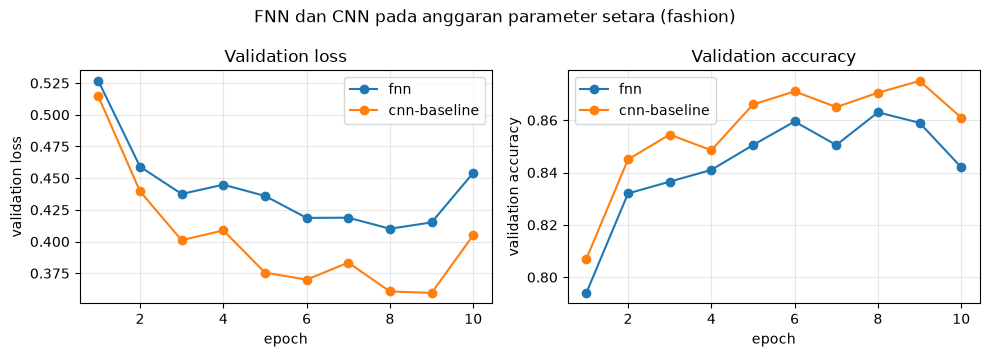

In [29]:
# BATCH, EPOCH, loader, evaluasi, dan jalankan sudah tersedia dari Bagian E.
# CNN baseline (cnn_baseline, riwayat_cnn, catatan_cnn) sudah dilatih di Bagian E; jangan dilatih ulang.
p_cnn = sum(q.numel() for q in cnn_baseline.parameters())
d_in = C_IN * H * W_IMG
kandidat = range(max(1, (p_cnn - 10) // (d_in + 11) - 2), (p_cnn - 10) // (d_in + 11) + 3)
hidden = min(kandidat, key=lambda h: abs((d_in + 11) * h + 10 - p_cnn))   # P(h) = (d+1)h + 10(h+1)
fnn_tugas = buat_fnn(hidden, c_in=C_IN, hw=H)
p_fnn = sum(q.numel() for q in fnn_tugas.parameters())
print(f'hidden={hidden} | parameter FNN={p_fnn:,} | CNN={p_cnn:,} | selisih={100 * abs(p_fnn - p_cnn) / p_cnn:.3f}%')
assert abs(p_fnn - p_cnn) / p_cnn < 0.01, 'anggaran belum setara (selisih > 1%)'

hasil, kurva, model_terlatih = [], {}, {}
# Latih FNN dengan protokol yang sama persis (Adam 1e-3, batch 128, 10 epoch, 790 update).
riwayat_fnn, catatan_fnn = jalankan(fnn_tugas, 'fnn')

# CNN baseline dari Bagian E dimasukkan apa adanya (tidak dilatih ulang).
hasil = [catatan_fnn, catatan_cnn]
kurva = {'fnn': riwayat_fnn, 'cnn-baseline': riwayat_cnn}
model_terlatih = {'fnn': fnn_tugas, 'cnn-baseline': cnn_baseline}

assert {c['run_id'] for c in hasil} == {'fnn', 'cnn-baseline'}, 'hasil harus memuat run FNN dan CNN baseline'
tabel = pd.DataFrame(hasil)
display(tabel[['run_id', 'parameter', 'perkalian', 'n_update', 'train_loss', 'val_loss',
               'val_acc', 'gap', 'detik_per_epoch']])
assert set(tabel['n_update']) == {790}, 'kedua model harus memakai 790 update'

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for label, r in kurva.items():
    axes[0].plot(r['epoch'], r['val_loss'], marker='o', label=label)
    axes[1].plot(r['epoch'], r['val_acc'], marker='o', label=label)
axes[0].set(xlabel='epoch', ylabel='validation loss', title='Validation loss')
axes[1].set(xlabel='epoch', ylabel='validation accuracy', title='Validation accuracy')
for ax in axes:
    ax.grid(alpha=.3)
    ax.legend()
fig.suptitle(f'FNN dan CNN pada anggaran parameter setara ({DATASET})')
plt.tight_layout()
plt.show()

In [30]:
r = tabel.set_index('run_id')
acc_cnn, acc_fnn = r.loc['cnn-baseline', 'val_acc'], r.loc['fnn', 'val_acc']
vl_cnn, vl_fnn = r.loc['cnn-baseline', 'val_loss'], r.loc['fnn', 'val_loss']
sel_acc = 100 * (acc_cnn - acc_fnn)
rasio_waktu = r.loc['cnn-baseline', 'detik_per_epoch'] / r.loc['fnn', 'detik_per_epoch']
rasio_mult = r.loc['cnn-baseline', 'perkalian'] / r.loc['fnn', 'perkalian']
pemenang = 'CNN baseline' if vl_cnn < vl_fnn else 'FNN'
pembanding_waktu = 'lebih kecil' if rasio_waktu < rasio_mult else 'lebih besar'
display(Markdown(f'''
**Penjelasan T2.** Pada anggaran parameter setara (CNN {p_cnn:,} dan FNN {p_fnn:,}), **{pemenang}** menang berdasarkan validation loss: {vl_cnn:.4f} untuk CNN dan {vl_fnn:.4f} untuk FNN. Accuracy validasi CNN {acc_cnn:.4f} dan FNN {acc_fnn:.4f}, selisih **{sel_acc:+.2f} poin persentase** (CNN dikurangi FNN).

Rasio waktu per epoch CNN/FNN yang terukur adalah **{rasio_waktu:.2f}**, sedangkan rasio perkalian CNN/FNN adalah **{rasio_mult:.2f}**; rasio waktu {pembanding_waktu} daripada rasio perkalian. Jumlah perkalian bukan satu-satunya penentu waktu, karena satu epoch juga memuat biaya tetap (DataLoader, optimizer Adam, backward) dan kecepatan tiap operasi bergantung pada seberapa baik ia dioptimalkan oleh pustaka CPU.
'''))



**Penjelasan T2.** Pada anggaran parameter setara (CNN 421,642 dan FNN 421,360), **CNN baseline** menang berdasarkan validation loss: 0.4050 untuk CNN dan 0.4542 untuk FNN. Accuracy validasi CNN 0.8610 dan FNN 0.8420, selisih **+1.90 poin persentase** (CNN dikurangi FNN).

Rasio waktu per epoch CNN/FNN yang terukur adalah **9.22**, sedangkan rasio perkalian CNN/FNN adalah **10.08**; rasio waktu lebih kecil daripada rasio perkalian. Jumlah perkalian bukan satu-satunya penentu waktu, karena satu epoch juga memuat biaya tetap (DataLoader, optimizer Adam, backward) dan kecepatan tiap operasi bergantung pada seberapa baik ia dioptimalkan oleh pustaka CPU.


## Tugas T3. Kernel, feature map, dan kernel Sobel manual — bagian dari 20 poin · Tugas Individu

blok 1: (32, 28, 28) | aktivasi nol 42.8%
blok 2: (64, 14, 14) | aktivasi nol 66.5%
[OK] Sobel x: corr2d vs F.conv2d: shape (26, 26)
[OK] Sobel y: corr2d vs F.conv2d: shape (26, 26)
kernel terlatih paling mirip Sobel x: [17, 19, 10] | Sobel y: [13, 29, 11]


,kanal,cos_Sobel_x,cos_Sobel_y
10,10,0.7618,0.3735
11,11,0.0118,0.5461
13,13,0.2951,0.7511
17,17,0.9015,0.0224
19,19,0.7795,0.2169
29,29,0.2594,0.5863


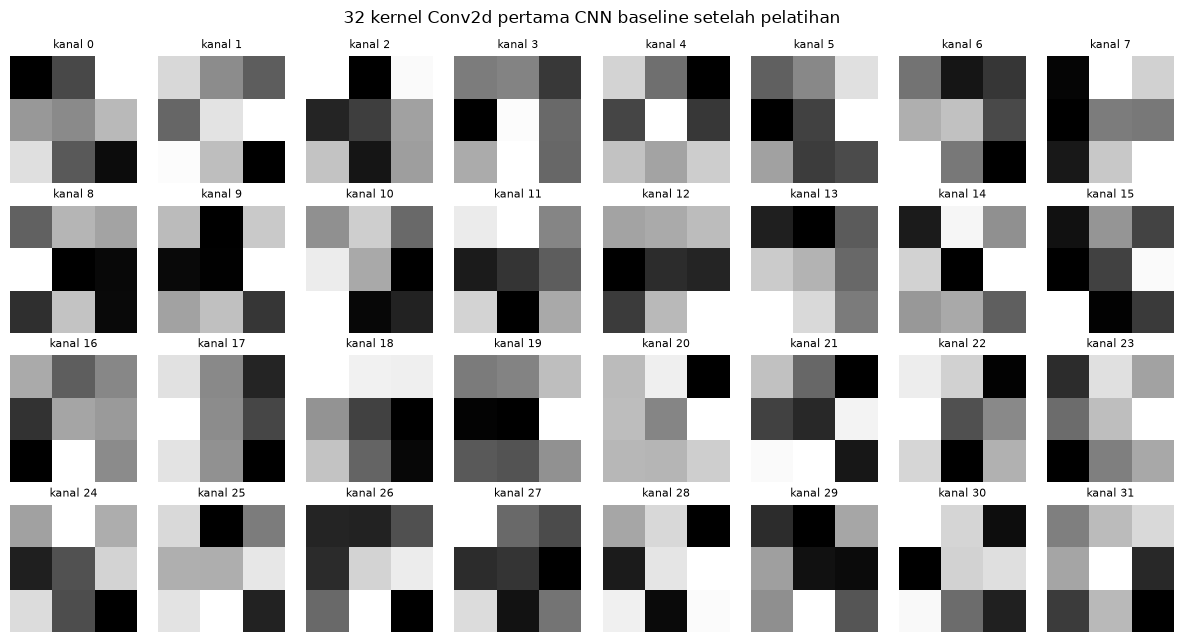

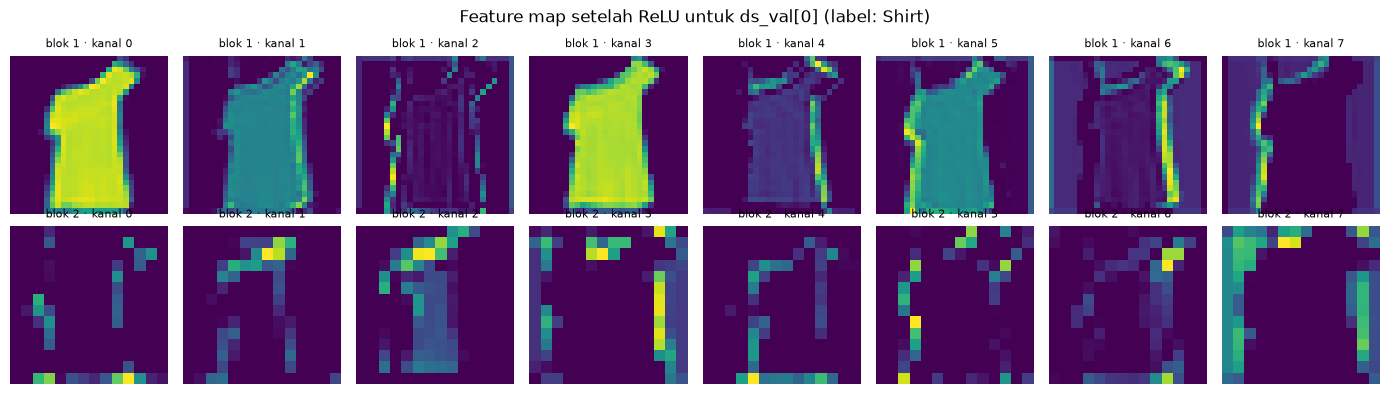

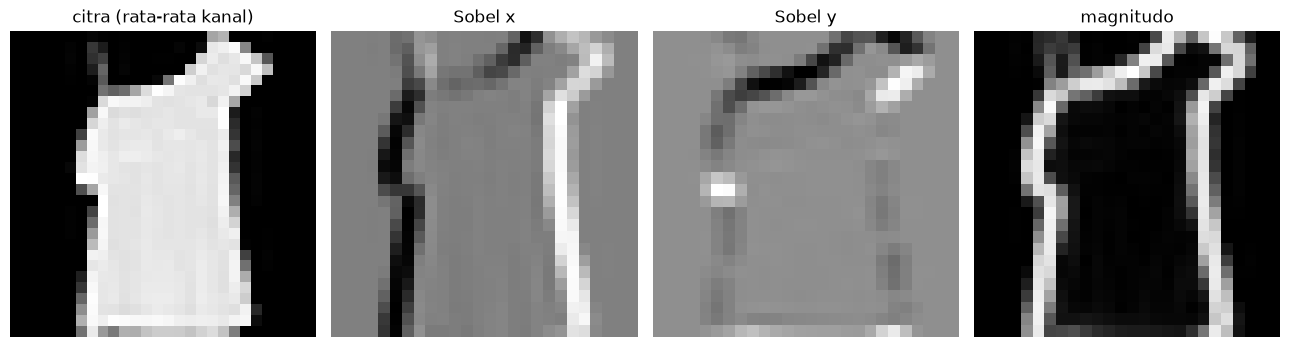

In [31]:
# ---------- T3a: 32 kernel Conv2d pertama setelah pelatihan ----------
W1 = cnn_baseline[0].weight.detach().cpu()           # (32, C_in, 3, 3)
fig, axes = plt.subplots(4, 8, figsize=(12, 6.5))
for i, ax in enumerate(axes.flat):
    ki = W1[i]
    if C_IN == 3:
        ax.imshow(((ki - ki.min()) / (ki.max() - ki.min() + 1e-8)).permute(1, 2, 0).numpy())
    else:
        ax.imshow(ki[0].numpy(), cmap='gray')
    ax.set_title(f'kanal {i}', fontsize=8)
    ax.axis('off')
fig.suptitle('32 kernel Conv2d pertama CNN baseline setelah pelatihan')
plt.tight_layout()
plt.show()

# ---------- T3b: delapan feature map setelah ReLU, blok 1 dan blok 2 ----------
x0 = ds_val[0][0][None].to(DEVICE)
cnn_baseline.eval()
with torch.no_grad():
    f1 = cnn_baseline[1](cnn_baseline[0](x0))                          # Conv -> ReLU (blok 1)
    f2 = cnn_baseline[4](cnn_baseline[3](cnn_baseline[2](f1)))         # Pool -> Conv -> ReLU (blok 2)
f1, f2 = f1[0].cpu(), f2[0].cpu()

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for j in range(8):
    axes[0, j].imshow(f1[j].numpy(), cmap='viridis')
    axes[0, j].set_title(f'blok 1 · kanal {j}', fontsize=8)
    axes[1, j].imshow(f2[j].numpy(), cmap='viridis')
    axes[1, j].set_title(f'blok 2 · kanal {j}', fontsize=8)
    axes[0, j].axis('off')
    axes[1, j].axis('off')
fig.suptitle(f'Feature map setelah ReLU untuk ds_val[0] (label: {KELAS[int(ds_val[0][1])]})')
plt.tight_layout()
plt.show()
sparsitas1 = 100 * float((f1 == 0).float().mean())
sparsitas2 = 100 * float((f2 == 0).float().mean())
print(f'blok 1: {tuple(f1.shape)} | aktivasi nol {sparsitas1:.1f}%')
print(f'blok 2: {tuple(f2.shape)} | aktivasi nol {sparsitas2:.1f}%')

# ---------- T3c: kernel Sobel manual ----------
img = ds_val[0][0].mean(0).to(DT)                    # rata-rata kanal, float64, (H, W)
Sx = torch.tensor([[1, 0, -1], [2, 0, -2], [1, 0, -1]], dtype=DT)
Sy = torch.tensor([[1, 2, 1], [0, 0, 0], [-1, -2, -1]], dtype=DT)
gx, gy = corr2d(img, Sx), corr2d(img, Sy)
cek('Sobel x: corr2d vs F.conv2d', gx, F.conv2d(img[None, None], Sx[None, None])[0, 0])
cek('Sobel y: corr2d vs F.conv2d', gy, F.conv2d(img[None, None], Sy[None, None])[0, 0])
magnitudo = torch.sqrt(gx ** 2 + gy ** 2)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, data, judul in zip(axes, [img, gx, gy, magnitudo],
                           ['citra (rata-rata kanal)', 'Sobel x', 'Sobel y', 'magnitudo']):
    ax.imshow(data.numpy(), cmap='gray')
    ax.set_title(judul)
    ax.axis('off')
plt.tight_layout()
plt.show()

# Kemiripan kosinus (nilai mutlak) kernel terlatih dengan Sobel, setelah dirata-ratakan antarkanal masukan.
Wk = W1.mean(1).to(DT).reshape(W1.shape[0], -1)
def kemiripan(S):
    s = S.reshape(-1)
    return (Wk @ s).abs() / (Wk.norm(dim=1) * s.norm() + 1e-12)
cx, cy = kemiripan(Sx), kemiripan(Sy)
idx_sobel_x = cx.topk(3).indices.tolist()
idx_sobel_y = cy.topk(3).indices.tolist()
tabel_sobel = pd.DataFrame({'kanal': list(range(W1.shape[0])), 'cos_Sobel_x': cx.numpy(), 'cos_Sobel_y': cy.numpy()})
display(tabel_sobel.loc[sorted(set(idx_sobel_x + idx_sobel_y))])
print('kernel terlatih paling mirip Sobel x:', idx_sobel_x, '| Sobel y:', idx_sobel_y)


In [32]:
ket_x = ', '.join(f'{i} (cos {float(cx[i]):.2f})' for i in idx_sobel_x)
ket_y = ', '.join(f'{i} (cos {float(cy[i]):.2f})' for i in idx_sobel_y)
display(Markdown(f'''
**Penjelasan T3.** *Beda watak feature map.* Feature map blok pertama ({tuple(f1.shape)}) masih berukuran sama dengan citra dan menyerupai versi tersaring dari citra asli: siluet, tepi, dan kontras lokal masih mudah dikenali karena receptive field-nya hanya 3x3. Feature map blok kedua ({tuple(f2.shape)}) lebih kecil, lebih kasar, dan lebih abstrak; receptive field-nya 10x10 sehingga satu unit merespons pola yang lebih besar (bagian pakaian atau bentuk sepatu) dan bukan lagi tepi tunggal, sehingga sulit dibaca sebagai citra. Aktivasi nol setelah ReLU juga lebih banyak pada blok kedua ({sparsitas2:.1f}% dibanding {sparsitas1:.1f}% pada blok pertama), yang berarti unit-unit lebih selektif.

*Kernel mirip Sobel.* Berdasarkan kemiripan kosinus, kernel terlatih yang paling menyerupai Sobel x (tepi vertikal) adalah kanal {ket_x}, dan yang paling menyerupai Sobel y (tepi horizontal) adalah kanal {ket_y}. Nilai kosinus mendekati 1 berarti pola bobotnya hampir sama dengan Sobel (tanda boleh terbalik); nilai yang rendah berarti kernel itu belajar pola lain, misalnya pendeteksi bercak atau gradien diagonal. Kecocokan visual dapat diperiksa pada gambar 32 kernel di atas.
'''))



**Penjelasan T3.** *Beda watak feature map.* Feature map blok pertama ((32, 28, 28)) masih berukuran sama dengan citra dan menyerupai versi tersaring dari citra asli: siluet, tepi, dan kontras lokal masih mudah dikenali karena receptive field-nya hanya 3x3. Feature map blok kedua ((64, 14, 14)) lebih kecil, lebih kasar, dan lebih abstrak; receptive field-nya 10x10 sehingga satu unit merespons pola yang lebih besar (bagian pakaian atau bentuk sepatu) dan bukan lagi tepi tunggal, sehingga sulit dibaca sebagai citra. Aktivasi nol setelah ReLU juga lebih banyak pada blok kedua (66.5% dibanding 42.8% pada blok pertama), yang berarti unit-unit lebih selektif.

*Kernel mirip Sobel.* Berdasarkan kemiripan kosinus, kernel terlatih yang paling menyerupai Sobel x (tepi vertikal) adalah kanal 17 (cos 0.90), 19 (cos 0.78), 10 (cos 0.76), dan yang paling menyerupai Sobel y (tepi horizontal) adalah kanal 13 (cos 0.75), 29 (cos 0.59), 11 (cos 0.55). Nilai kosinus mendekati 1 berarti pola bobotnya hampir sama dengan Sobel (tanda boleh terbalik); nilai yang rendah berarti kernel itu belajar pola lain, misalnya pendeteksi bercak atau gradien diagonal. Kecocokan visual dapat diperiksa pada gambar 32 kernel di atas.


## Tugas T4. Evaluasi akhir — bagian dari 20 poin · Tugas Individu

model terpilih: cnn-baseline | val_loss = 0.405
kesalahan terbanyak (terarah): Shirt -> T-shirt/top = 56 citra
pasangan paling sering tertukar: T-shirt/top <-> Shirt = 62 citra
TEST (sekali) | model cnn-baseline | loss 0.3899 | accuracy 0.8659


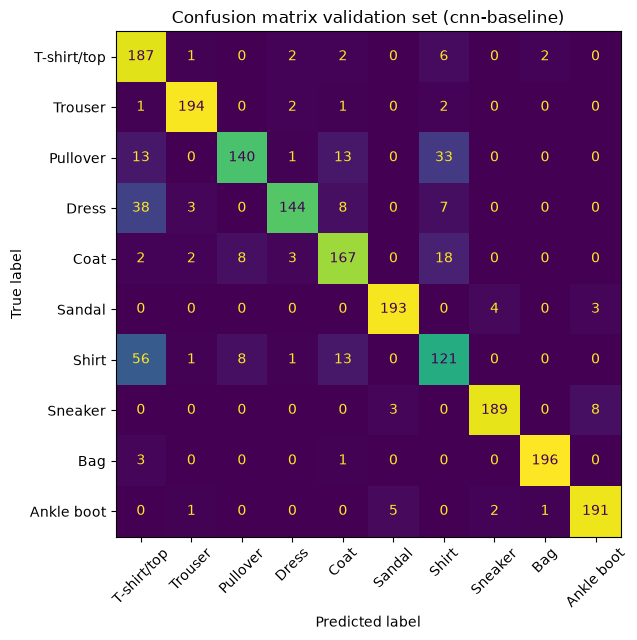

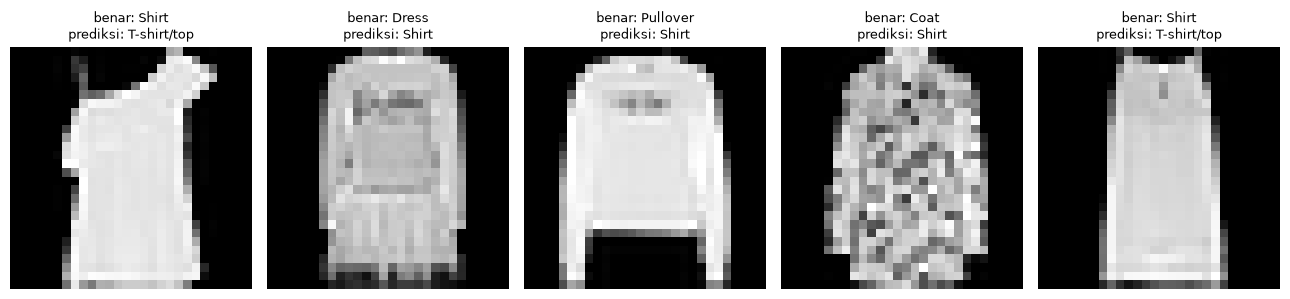

In [33]:
# T4a: pilih model dengan validation loss terendah (hanya validation set yang dipakai).
nama_terbaik = tabel.loc[tabel['val_loss'].idxmin(), 'run_id']
model_terbaik = model_terlatih[nama_terbaik].to(DEVICE).eval()
print('model terpilih:', nama_terbaik, '| val_loss =', round(float(tabel['val_loss'].min()), 4))

@torch.no_grad()
def prediksi(model, ds, batch=512):
    model.eval()
    keluar = []
    for xb, _ in loader(ds, batch, False):
        keluar.append(model(xb.to(DEVICE)).argmax(1).cpu())
    return torch.cat(keluar)

# T4b: confusion matrix pada validation set dan pasangan kelas yang paling sering tertukar.
pred_val = prediksi(model_terbaik, ds_val)
cm = confusion_matrix(y_val.numpy(), pred_val.numpy())
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay(cm, display_labels=KELAS).plot(ax=ax, xticks_rotation=45, colorbar=False)
ax.set_title(f'Confusion matrix validation set ({nama_terbaik})')
plt.tight_layout()
plt.show()

cm_salah = cm.copy()
np.fill_diagonal(cm_salah, 0)
a_, b_ = np.unravel_index(cm_salah.argmax(), cm_salah.shape)
pasangan = max(((i, j) for i in range(len(KELAS)) for j in range(i + 1, len(KELAS))),
               key=lambda ij: cm[ij[0], ij[1]] + cm[ij[1], ij[0]])
print(f'kesalahan terbanyak (terarah): {KELAS[a_]} -> {KELAS[b_]} = {cm_salah[a_, b_]} citra')
print(f'pasangan paling sering tertukar: {KELAS[pasangan[0]]} <-> {KELAS[pasangan[1]]} = '
      f'{cm[pasangan[0], pasangan[1]] + cm[pasangan[1], pasangan[0]]} citra')

# T4c: lima prediksi salah beserta label benar dan label prediksi.
idx_salah = (pred_val != y_val).nonzero().flatten()[:5].tolist()
salah = [(i, KELAS[int(y_val[i])], KELAS[int(pred_val[i])]) for i in idx_salah]
fig, axes = plt.subplots(1, 5, figsize=(13, 3))
for ax, (i, benar, pred) in zip(axes, salah):
    gambar = X_val[i]
    if C_IN == 3:
        ax.imshow(gambar.permute(1, 2, 0).numpy())
    else:
        ax.imshow(gambar[0].numpy(), cmap='gray')
    ax.set_title(f'benar: {benar}\nprediksi: {pred}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

# T4d: test set dibuat dan dievaluasi SATU KALI pada tahap ini.
ds_uji = TensorDataset(normalkan(X_uji_mentah), y_uji)
uji_loss, uji_acc = evaluasi(model_terbaik, ds_uji)
print(f'TEST (sekali) | model {nama_terbaik} | loss {uji_loss:.4f} | accuracy {uji_acc:.4f}')


In [34]:
PENYEBAB = {
    frozenset({'T-shirt/top', 'Shirt'}): 'siluet atasan dan lengan hampir sama; pembeda (kerah, kancing) sangat halus pada 28x28',
    frozenset({'Pullover', 'Coat'}): 'bentuk badan dan lengan panjang serupa; pembeda seperti resleting atau kancing kecil',
    frozenset({'Pullover', 'Shirt'}): 'sama-sama berlengan panjang dengan tekstur polos; kerah dan kancing sulit terlihat',
    frozenset({'Coat', 'Shirt'}): 'siluet berlengan panjang mirip; panjang dan bukaan depan tidak jelas pada resolusi rendah',
    frozenset({'Sandal', 'Sneaker'}): 'sama-sama alas kaki rendah; tali sandal tipis mudah tampak seperti pola sneaker',
    frozenset({'Sneaker', 'Ankle boot'}): 'bentuk sol dan bagian depan mirip; tinggi leher sepatu tidak selalu jelas',
    frozenset({'Sandal', 'Ankle boot'}): 'orientasi sepatu miring dan bukaan atas sandal tampak seperti leher bot',
    frozenset({'T-shirt/top', 'Dress'}): 'badan atas serupa; panjang bawahan tidak terlihat jelas bila citra terpotong atau pendek',
    frozenset({'Dress', 'Coat'}): 'siluet vertikal panjang mirip; bukaan depan dan lengan kurang kontras',
    frozenset({'Trouser', 'Dress'}): 'dress sempit memanjang dapat menyerupai dua kaki celana',
}
UMUM = 'siluet dan tekstur kedua kelas mirip pada resolusi rendah sehingga fitur pembeda halus tidak tertangkap'
baris_md = ['| No | Label benar | Prediksi | Dugaan penyebab |', '|----|-------------|----------|-----------------|']
for no, (i, benar, pred) in enumerate(salah, start=1):
    sebab = PENYEBAB.get(frozenset({benar, pred}), UMUM)
    baris_md.append(f'| {no} | {benar} | {pred} | {sebab} |')
display(Markdown('**Analisis lima kesalahan.**\n\n' + '\n'.join(baris_md)))


**Analisis lima kesalahan.**

| No | Label benar | Prediksi | Dugaan penyebab |
|----|-------------|----------|-----------------|
| 1 | Shirt | T-shirt/top | siluet atasan dan lengan hampir sama; pembeda (kerah, kancing) sangat halus pada 28x28 |
| 2 | Dress | Shirt | siluet dan tekstur kedua kelas mirip pada resolusi rendah sehingga fitur pembeda halus tidak tertangkap |
| 3 | Pullover | Shirt | sama-sama berlengan panjang dengan tekstur polos; kerah dan kancing sulit terlihat |
| 4 | Coat | Shirt | siluet berlengan panjang mirip; panjang dan bukaan depan tidak jelas pada resolusi rendah |
| 5 | Shirt | T-shirt/top | siluet atasan dan lengan hampir sama; pembeda (kerah, kancing) sangat halus pada 28x28 |

In [35]:
tabel_metrics = tabel.copy()
tabel_metrics.insert(0, 'module', 'M05')
tabel_metrics.insert(1, 'student_id', NIM)
tabel_metrics.to_csv(f'M05_{NIM}_metrics.csv', index=False)
print(f'{len(tabel_metrics)} baris tersimpan ke M05_{NIM}_metrics.csv')
assert len(tabel_metrics) == 2, 'metrics.csv harus memuat run FNN dan CNN baseline'

2 baris tersimpan ke M05_123450121_metrics.csv


In [36]:
alasan_pemenang = (
    "CNN memanfaatkan *sparse connectivity* (tiap unit hanya melihat tetangga 3x3 sehingga bobotnya dipakai untuk pola lokal, bukan hubungan acak antarpiksel) dan *parameter sharing* (kernel yang sama dipakai di semua posisi, sehingga pola yang dipelajari di satu tempat otomatis berlaku di tempat lain). Pada anggaran parameter yang sama, FNN menghabiskan hampir seluruh bobotnya untuk pemetaan padat piksel-ke-unit tanpa asumsi spasial."
    if vl_cnn < vl_fnn else
    "Pada eksperimen ini FNN tidak kalah, yang masuk akal karena Fashion-MNIST berukuran kecil, objeknya terpusat, dan hanya 10 epoch pada 10.000 citra dipakai. Keunggulan CNN (*sparse connectivity* dan *parameter sharing*) biasanya baru jelas pada citra yang lebih besar atau objeknya bergeser; keduanya tetap merupakan alasan CNN lebih hemat parameter per kemampuan."
)
alasan_waktu = (
    "Rasio waktu lebih kecil daripada rasio perkalian karena waktu satu epoch tidak hanya perkalian: ada biaya tetap yang hampir sama untuk kedua model (pemuatan batch, optimizer, overhead Python), dan konvolusi dijalankan oleh kernel CPU yang sangat dioptimalkan sehingga efisiensi per perkaliannya tinggi."
    if rasio_waktu < rasio_mult else
    "Rasio waktu lebih besar daripada rasio perkalian karena konvolusi punya intensitas aritmetika lebih rendah per byte dibanding perkalian matriks padat pada FNN: peta aktivasi besar harus ditulis dan dibaca ulang (konv, ReLU, pooling), dan backward konvolusi lebih mahal; perkalian matriks FNN sangat efisien dijalankan oleh BLAS."
)

bagian_statis_1 = r'''
## Pertanyaan analisis

**1. Mengapa gradien terhadap masukan memerlukan kernel yang dibalik, sedangkan gradien terhadap kernel tidak?**
Pada forward, $X_{i,j}$ dipakai oleh keluaran $Y_{i-u,\,j-v}$ dengan bobot $K_{u,v}$: ketika indeks kernel $(u,v)$ bertambah, posisi keluaran $(i-u,\,j-v)$ justru berkurang. Maka $\partial\mathcal{L}/\partial X_{i,j}=\sum_{u,v}G_{i-u,\,j-v}K_{u,v}$, yaitu arah indeks $\mathbf{G}$ berlawanan dengan arah $\mathbf{K}$, yang setara dengan korelasi $\mathbf{G}$ berpadding dengan $\operatorname{rot180}(\mathbf{K})$. Pada Bagian D, $X_{1,1}$ dipakai oleh empat keluaran: $Y_{0,0}$ dengan $K_{1,1}=0$, $Y_{0,1}$ dengan $K_{1,0}=2$, $Y_{1,0}$ dengan $K_{0,1}=-1$, dan $Y_{1,1}$ dengan $K_{0,0}=1$. Dengan $\mathbf{G}=\left[\begin{smallmatrix}1&0\\-1&2\end{smallmatrix}\right]$ diperoleh $\partial\mathcal{L}/\partial X_{1,1}=1\cdot0+0\cdot2+(-1)(-1)+2\cdot1=3$, sama dengan elemen tengah `DX_TANGAN`. Sebaliknya, $\partial\mathcal{L}/\partial K_{u,v}=\sum_{i,j}G_{i,j}X_{i+u,\,j+v}$: indeks $\mathbf{X}$ dan $\mathbf{K}$ naik bersama, sehingga tidak ada pembalikan dan hasilnya langsung $\mathbf{X}\star\mathbf{G}$.

**2. Pada stride 2, apa yang terjadi pada baris dan kolom masukan yang tidak dikunjungi jendela?**
Bila $(n+2p-k)\bmod s\neq0$, ada baris dan kolom terakhir yang tidak pernah masuk ke jendela mana pun (contoh: indeks 5 pada konfigurasi `(1, 2, 6, 3, 2, 0)`). Nilai-nilai itu tidak memengaruhi keluaran maupun loss, sehingga gradiennya tepat nol dan informasi di sana hilang. Pada implementasi, itu sebabnya $\partial\mathcal{L}/\partial\mathbf{X}$ perlu ditambah nol agar ukurannya kembali ke $n+2p$.
'''

bagian_dinamis = f'''
**3. Model mana yang menang pada anggaran parameter yang praktis sama?**
Berdasarkan validation loss, **{pemenang}** menang; selisih accuracy validasi CNN dikurangi FNN adalah **{sel_acc:+.2f} poin persentase** ({acc_cnn:.4f} lawan {acc_fnn:.4f}). {alasan_pemenang}

**4. Rasio waktu per epoch yang terukur**
Rasio perkalian CNN/FNN adalah **{rasio_mult:.2f}** (sekitar sepuluh kali pada Fashion-MNIST; sekitar sebelas kali pada masukan CIFAR-10 3x32x32), sedangkan rasio waktu per epoch yang saya ukur adalah **{rasio_waktu:.2f}**. {alasan_waktu}
'''

bagian_statis_2 = r'''
**5. Apakah receptive field 10x10 cukup untuk mengenali objek berukuran 32x32?**
Tidak cukup bila dilihat per unit: 10x10 hanya menutup sekitar 10% luas citra 32x32 (100 dari 1024 piksel), sehingga satu unit keluaran blok kedua hanya melihat sebagian objek. Informasi di luar wilayah itu digabungkan oleh `Flatten` dan `Linear(4096, 128)`: setiap neuron lapisan penuh ini terhubung ke seluruh 8x8 posisi peta fitur, yang gabungan receptive field-nya menutup seluruh citra, lalu `Linear(128, 10)` mengambil keputusan kelas. Receptive field juga dapat diperluas dengan menambah blok konvolusi/pooling, kernel lebih besar, atau stride.
'''
display(Markdown(bagian_statis_1 + bagian_dinamis + bagian_statis_2))



## Pertanyaan analisis

**1. Mengapa gradien terhadap masukan memerlukan kernel yang dibalik, sedangkan gradien terhadap kernel tidak?**
Pada forward, $X_{i,j}$ dipakai oleh keluaran $Y_{i-u,\,j-v}$ dengan bobot $K_{u,v}$: ketika indeks kernel $(u,v)$ bertambah, posisi keluaran $(i-u,\,j-v)$ justru berkurang. Maka $\partial\mathcal{L}/\partial X_{i,j}=\sum_{u,v}G_{i-u,\,j-v}K_{u,v}$, yaitu arah indeks $\mathbf{G}$ berlawanan dengan arah $\mathbf{K}$, yang setara dengan korelasi $\mathbf{G}$ berpadding dengan $\operatorname{rot180}(\mathbf{K})$. Pada Bagian D, $X_{1,1}$ dipakai oleh empat keluaran: $Y_{0,0}$ dengan $K_{1,1}=0$, $Y_{0,1}$ dengan $K_{1,0}=2$, $Y_{1,0}$ dengan $K_{0,1}=-1$, dan $Y_{1,1}$ dengan $K_{0,0}=1$. Dengan $\mathbf{G}=\left[\begin{smallmatrix}1&0\\-1&2\end{smallmatrix}\right]$ diperoleh $\partial\mathcal{L}/\partial X_{1,1}=1\cdot0+0\cdot2+(-1)(-1)+2\cdot1=3$, sama dengan elemen tengah `DX_TANGAN`. Sebaliknya, $\partial\mathcal{L}/\partial K_{u,v}=\sum_{i,j}G_{i,j}X_{i+u,\,j+v}$: indeks $\mathbf{X}$ dan $\mathbf{K}$ naik bersama, sehingga tidak ada pembalikan dan hasilnya langsung $\mathbf{X}\star\mathbf{G}$.

**2. Pada stride 2, apa yang terjadi pada baris dan kolom masukan yang tidak dikunjungi jendela?**
Bila $(n+2p-k)\bmod s\neq0$, ada baris dan kolom terakhir yang tidak pernah masuk ke jendela mana pun (contoh: indeks 5 pada konfigurasi `(1, 2, 6, 3, 2, 0)`). Nilai-nilai itu tidak memengaruhi keluaran maupun loss, sehingga gradiennya tepat nol dan informasi di sana hilang. Pada implementasi, itu sebabnya $\partial\mathcal{L}/\partial\mathbf{X}$ perlu ditambah nol agar ukurannya kembali ke $n+2p$.

**3. Model mana yang menang pada anggaran parameter yang praktis sama?**
Berdasarkan validation loss, **CNN baseline** menang; selisih accuracy validasi CNN dikurangi FNN adalah **+1.90 poin persentase** (0.8610 lawan 0.8420). CNN memanfaatkan *sparse connectivity* (tiap unit hanya melihat tetangga 3x3 sehingga bobotnya dipakai untuk pola lokal, bukan hubungan acak antarpiksel) dan *parameter sharing* (kernel yang sama dipakai di semua posisi, sehingga pola yang dipelajari di satu tempat otomatis berlaku di tempat lain). Pada anggaran parameter yang sama, FNN menghabiskan hampir seluruh bobotnya untuk pemetaan padat piksel-ke-unit tanpa asumsi spasial.

**4. Rasio waktu per epoch yang terukur**
Rasio perkalian CNN/FNN adalah **10.08** (sekitar sepuluh kali pada Fashion-MNIST; sekitar sebelas kali pada masukan CIFAR-10 3x32x32), sedangkan rasio waktu per epoch yang saya ukur adalah **9.22**. Rasio waktu lebih kecil daripada rasio perkalian karena waktu satu epoch tidak hanya perkalian: ada biaya tetap yang hampir sama untuk kedua model (pemuatan batch, optimizer, overhead Python), dan konvolusi dijalankan oleh kernel CPU yang sangat dioptimalkan sehingga efisiensi per perkaliannya tinggi.

**5. Apakah receptive field 10x10 cukup untuk mengenali objek berukuran 32x32?**
Tidak cukup bila dilihat per unit: 10x10 hanya menutup sekitar 10% luas citra 32x32 (100 dari 1024 piksel), sehingga satu unit keluaran blok kedua hanya melihat sebagian objek. Informasi di luar wilayah itu digabungkan oleh `Flatten` dan `Linear(4096, 128)`: setiap neuron lapisan penuh ini terhubung ke seluruh 8x8 posisi peta fitur, yang gabungan receptive field-nya menutup seluruh citra, lalu `Linear(128, 10)` mengambil keputusan kelas. Receptive field juga dapat diperluas dengan menambah blok konvolusi/pooling, kernel lebih besar, atau stride.


## Checklist sebelum mengumpulkan

- [x] Identitas, seed, versi library, device, dan dataset tercantum.
- [x] Setiap hitungan tangan berada pada sel sebelum kode verifikasinya.
- [x] Implementasi manual tidak memanggil `F.conv2d` maupun autograd.
- [x] Seluruh sel `cek` dan `assert` lolos pada `float64`.
- [x] Tabel anatomi memuat shape, parameter, perkalian, dan receptive field untuk kedua model.
- [x] Kedua run memakai data, seed, dan 790 update yang sama.
- [x] Test set hanya dipanggil satu kali pada Tugas T4.
- [x] `metrics.csv` memuat kedua run.
- [x] Notebook lolos *Restart Kernel and Run All*.